# Calibration-free P300: does a decoder trained on other people work on a new user?

**ROBT613 Midterm Project**
Birzhan Zhunusbekov, Arman Abakov, Nazerke Khamzina, Bekmurat Amangeldiyev
Topic registered: 2026-10-15.

**Dataset:** BrainInvaders2013a (Vaineau et al., 2019), loaded with MOABB → MNE.
**Idea:** cross-subject generalization (Challenging).

**Hypothesis.** A shrinkage-LDA P300 detector trained only on *other* subjects
(leave-one-subject-out, LOSO) reaches above-chance ROC AUC on an unseen Brain Invaders
user, but scores lower than a subject-specific detector evaluated on the same held-out
run — and the gap remains when both detectors get the same number of training epochs.

**Why it matters.** Every P300 session normally starts with a calibration phase. If a
generic decoder works out of the box, a user can start immediately; the Brain Invaders
adaptive mode was built on exactly this idea (Barachant & Congedo, 2014). The question
here is how much a *linear, in-scope* decoder loses when it skips calibration, and for whom.

The notebook covers audit, signal inspection, artifact handling, P300 physiology,
grouped decoding, controlled comparisons, and reproducibility. Actual completion
is established by saved outputs and the run manifest at the end.

**Development disclosure.** Subjects 8-10 informed preprocessing choices in the
earlier pilot. Before the full run, the feature montage was fixed to Cz/P3/Pz/P4/Oz.
This removes the earlier GLOBAL_BADS dependency. Sensitivity results exclude
development subjects from evaluation. The original hypothesis is unchanged.

Methods and code are adapted from the ROBT613 BCI Workshop notebooks 00–06
(https://github.com/berdakh/ROBT613-BCI-Workshop); each reused block cites its notebook.

## 0 · Setup
Versions are pinned to the workshop's `requirements.txt` (mne 1.13.2, moabb 1.7.2).
On Colab the first cell installs them; restart the runtime if pip asks for it.

In [1]:
# Setup pattern adapted from workshop notebook 01 (setup cell).
import sys, subprocess, os, time
T_SETUP_START = time.perf_counter()
numpy_loaded_before_install = getattr(sys.modules.get('numpy'), '__version__', None)
if 'google.colab' in sys.modules:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q',
                           'mne==1.13.2', 'moabb==1.7.2', 'numpy==2.5.4',
                           'scipy==1.18.1', 'pandas==2.3.3', 'scikit-learn==1.9.1',
                           'matplotlib==3.11.2', 'PyYAML==6.0.3', 'remotezip==0.12.6',
                           'threadpoolctl==3.7.0'])
    if numpy_loaded_before_install not in (None, '2.5.4'):
        raise RuntimeError('NumPy was upgraded while already loaded. Choose Runtime > Restart session and run all, then confirm Yes. The installed packages remain available.')
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mne
import scipy.linalg, sklearn  # load native pools before limiting their thread counts
from threadpoolctl import threadpool_limits, threadpool_info
NATIVE_THREAD_LIMIT = threadpool_limits(limits=1)  # bound BLAS/OpenMP work on a small CPU runtime
from IPython import get_ipython
if get_ipython() is not None:
    get_ipython().run_line_magic('matplotlib', 'inline')

SEED = 613
T_START = time.perf_counter()          # total runtime, printed in stage 7
rng = np.random.default_rng(SEED)
DEFAULT_DATA_DIR = './mne_data_colab' if 'google.colab' in sys.modules else './mne_data'
DATA_ROOT = Path(os.environ.get('BCI_DATA', DEFAULT_DATA_DIR)).resolve()
COLD_CACHE_AT_START = not DATA_ROOT.exists()
DATA_ROOT.mkdir(parents=True, exist_ok=True)
os.environ['MNE_DATA'] = str(DATA_ROOT)
# MOABB 1.7.2 prefers the NEMAR mirror, which holds only one file per session for
# BI2013a (3.mat = Non-Adaptive Training). With the mirror, the Adaptive Training run
# would be missing without any error, so we download the full Zenodo archives instead.
os.environ['MOABB_DOWNLOAD_PROVIDER'] = 'upstream'
mne.set_log_level('WARNING')
plt.rcParams.update({'figure.figsize': (9, 4), 'font.size': 11,
                     'axes.spines.top': False, 'axes.spines.right': False})
import importlib.metadata as metadata
print({p: metadata.version(p) for p in ['mne', 'moabb', 'numpy', 'scipy', 'scikit-learn']})
print('Dataset cache:', DATA_ROOT)

{'mne': '1.13.2', 'moabb': '1.7.2', 'numpy': '2.5.4', 'scipy': '1.18.1', 'scikit-learn': '1.9.1'}
Dataset cache: /content/mne_data_colab


### Study configuration
**Subject subset.** BrainInvaders2013a has 24 subjects. Subjects 1–7 recorded eight
sessions each, and the MOABB loader downloads all eight (≈1 GB per subject), which does
not fit the 30-minute Colab budget. Subjects 8–24 recorded exactly one session (≈130 MB
each, ≈2.2 GB in total), so every included subject contributes the same protocol and the
same amount of data. We therefore use **subjects 8–24 (n = 17)**.

**Runs.** Each session has a Non-Adaptive and an Adaptive run, each with a Training phase
(fixed 80 target / 400 non-target flashes) followed by an Online phase. We load only the
two **Training** phases: their flash counts are fixed, so every subject has the same class
balance, and the two runs give the within-subject baseline a leave-one-run-out split.
The run order was randomised per session (Vaineau et al., 2019), so MOABB's run name
(file number − 1) does not tell which condition a run is; we read it from each
subject's `meta.yml`.

In [2]:
SUBJECTS = list(range(8, 25))          # documented subset, see the text above
# Quick smoke test: BCI_N_SUBJECTS=1 audits only the first subject. Leave unset for the report.
AUDIT_SUBJECTS = SUBJECTS[:int(os.environ.get('BCI_N_SUBJECTS', len(SUBJECTS)))]
EVENT_ID = {'Target': 33285, 'NonTarget': 33286}
STIM_CHANNEL = 'STI 014'
# Group-level tests (Wilcoxon, Spearman) need enough subjects; below this they are skipped.
# BCI_MIN_GROUP_N=2 forces every group branch to run in a small smoke test (p-values meaningless).
MIN_GROUP_N = int(os.environ.get('BCI_MIN_GROUP_N', 6))

### Shared helper functions
All later stages call these functions instead of copying cells.

In [3]:
import yaml
from moabb.datasets import BI2013a


"""Fetch unmodified training MAT members from public Zenodo ZIPs using HTTP ranges.

This is archive retrieval only. MOABB's BI2013a reader still creates all MNE objects.
ZIP CRC is verified by RemoteZip; SHA-256 records the extracted local bytes.
"""
import hashlib,json,time,io,threading
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor, as_completed
import yaml
from remotezip import RemoteZip, RemoteFetcher, PartialBuffer
from requests import HTTPError
from email.utils import parsedate_to_datetime

_REQUEST_LOCK = threading.Lock()
_LAST_REQUEST = 0.0


class ParallelRangeFetcher(RemoteFetcher):
    """Bound streams, pace requests globally, and respect server retry instructions."""
    def _request(self, kwargs):
        global _LAST_REQUEST
        for attempt in range(6):
            with _REQUEST_LOCK:
                wait = 1.0 - (time.monotonic() - _LAST_REQUEST)
                if wait > 0: time.sleep(wait)
                _LAST_REQUEST = time.monotonic()
            try:
                return super()._request(kwargs)
            except HTTPError as error:
                response = error.response
                if response is None or response.status_code not in (429, 503) or attempt == 5:
                    raise
                retry_after = response.headers.get('Retry-After', '')
                try:
                    delay = max(1., float(retry_after))
                except ValueError:
                    try:
                        delay = max(1., parsedate_to_datetime(retry_after).timestamp() - time.time())
                    except (ValueError, TypeError):
                        delay = min(120., 15. * 2**attempt)
                response.close()
                with _REQUEST_LOCK:
                    _LAST_REQUEST = max(_LAST_REQUEST, time.monotonic() + delay)
                print(f'Zenodo requested a pause; retrying in {delay:.0f} s', flush=True)
                time.sleep(delay)

    def fetch(self, data_range, stream=False):
        first, last = data_range
        if first < 0 or last is None or last - first < 8 * 1024**2:
            return super().fetch(data_range, stream)
        blocks = [(a, min(a + 4 * 1024**2 - 1, last)) for a in range(first, last + 1, 4 * 1024**2)]
        def block(bounds):
            for attempt in range(3):
                try:
                    part = super(ParallelRangeFetcher, self).fetch(bounds, stream=False)
                    try:
                        data = part.read()
                        if part.tell() != bounds[1] + 1 or len(data) != bounds[1] - bounds[0] + 1:
                            raise IOError('Incomplete or incorrect HTTP byte range')
                        return data
                    finally:
                        part.close()
                except Exception:
                    if attempt == 2: raise
                    time.sleep(attempt + 1)
        with ThreadPoolExecutor(max_workers=2) as pool:
            data = b''.join(pool.map(block, blocks))
        return PartialBuffer(io.BytesIO(data), first, len(data), stream=False)


def existing_directory(root,subject):
    root=Path(root)
    for directory in [root/'BI2013a-training-only'/f'subject_{subject:02}',
                      root/'MNE-braininvaders2013-data/zenodo/2669187'/f'subject_{subject:02}']:
        meta_path=directory/'meta.yml'
        if not meta_path.exists():continue
        meta=yaml.safe_load(meta_path.read_text())
        names=[r['filename'] for r in meta['runs'] if r['type']=='training']
        paths=[directory/'Session1'/n.replace('.gdf','.mat') for n in names]
        if len(paths)==2 and all(p.exists() for p in paths):return directory,paths
    return None


def fetch_subject(root,subject):
    if not 8<=subject<=24:raise ValueError('This helper supports the declared single-session subset 8-24 only')
    found=existing_directory(root,subject)
    if found:return [str(p) for p in found[1]]
    directory=Path(root)/'BI2013a-training-only'/f'subject_{subject:02}'
    directory.mkdir(parents=True,exist_ok=True)
    url=f'https://zenodo.org/records/2669187/files/subject{subject:02}.zip?download=1'
    prefix=f'subject{subject:02}'
    log=[]
    for attempt in range(3):
        try:
            with RemoteZip(url,timeout=45,fetcher=ParallelRangeFetcher) as archive:
                meta_bytes=archive.read(f'{prefix}/meta.yml')
                meta=yaml.safe_load(meta_bytes)
                (directory/'meta.yml').write_bytes(meta_bytes)
                names=[r['filename'].replace('.gdf','.mat') for r in meta['runs'] if r['type']=='training']
                for name in names:
                    dest=directory/'Session1'/name
                    if dest.exists():continue
                    start=time.perf_counter()
                    data=archive.read(f'{prefix}/Session1/{name}')
                    dest.parent.mkdir(parents=True,exist_ok=True)
                    temporary=dest.with_suffix('.partial');temporary.write_bytes(data);temporary.replace(dest)
                    log.append(dict(member=f'{prefix}/Session1/{name}',bytes=len(data),
                                    sha256=hashlib.sha256(data).hexdigest(),seconds=time.perf_counter()-start))
            (directory/'download_manifest.json').write_text(json.dumps(dict(url=url,files=log),indent=2))
            return [str(directory/'Session1'/n) for n in names]
        except Exception:
            if attempt==2:raise
            time.sleep(2*(attempt+1))


def prepare_subjects(root,subjects,workers=4):
    start=time.perf_counter()
    with ThreadPoolExecutor(max_workers=workers) as pool:
        jobs={pool.submit(fetch_subject,root,s):s for s in subjects}
        for future in as_completed(jobs):
            paths=future.result()
            print(f'Training files ready: subject {jobs[future]} ({len(paths)} runs)',flush=True)
    print(f'Data preparation: {time.perf_counter()-start:.1f} s',flush=True)


class TrainingOnlyBI2013a(BI2013a):
    """Use official training MAT files; inherit MOABB's EEG-to-MNE loader unchanged."""
    def data_path(self, subject, path=None, force_update=False, update_path=None, verbose=None):
        if force_update:
            raise ValueError('Use a new cache directory to force a clean training-file download')
        return fetch_subject(DATA_ROOT, subject)


def make_dataset():
    return TrainingOnlyBI2013a(non_adaptive=True, adaptive=True, training=True, online=False)


def run_conditions(subject, dataset):
    """Map MOABB run name -> 'adaptive_training' etc., read from the subject's meta.yml."""
    first_file = Path(dataset.data_path(subject)[0])
    meta = yaml.safe_load((first_file.parents[1] / 'meta.yml').read_text())
    return {str(int(Path(r['filename']).stem) - 1): f"{r['experimental_condition']}_{r['type']}"
            for r in meta['runs']}


def load_subject_raws(subject, dataset=None):
    """Return a list of (session, run, condition, Raw) for one subject."""
    dataset = dataset or make_dataset()
    data = dataset.get_data(subjects=[subject])[subject]
    cond = run_conditions(subject, dataset)
    return [(sess, run, cond[run], raw) for sess, runs in data.items()
            for run, raw in runs.items()]


def count_events(raw):
    """Count Target / NonTarget flashes from the stimulus channel."""
    events = mne.find_events(raw, stim_channel=STIM_CHANNEL, shortest_event=1, verbose=False)
    codes, counts = np.unique(events[:, 2], return_counts=True)
    found = dict(zip(codes.tolist(), counts.tolist()))
    return {name: found.get(code, 0) for name, code in EVENT_ID.items()}, found, events


def band_sd(raw, l_freq=1.0, h_freq=20.0, edge_s=2.0):
    """Per-channel SD (V) in the P300 band, on a filtered copy; edges dropped.

    The amplifier is DC-coupled, so the raw SD is dominated by offsets and drift and
    says nothing about scaling. This audit-only filter does not touch `raw`;
    the real filter is chosen and justified in stage 2.
    """
    filt = raw.copy().filter(l_freq, h_freq, picks='eeg')
    edge = int(edge_s * raw.info['sfreq'])
    return filt.get_data(picks='eeg')[:, edge:-edge].std(axis=1)


def line_noise_db(raw, line=50.0):
    """Per-channel power at the mains frequency relative to 40–60 Hz neighbours (dB)."""
    psd = raw.compute_psd(picks='eeg', fmin=35, fmax=65, n_fft=1024)
    f, p = psd.freqs, psd.get_data()
    at_line = p[:, np.abs(f - line) <= 1].mean(axis=1)
    near = p[:, (np.abs(f - line) > 2) & (np.abs(f - line) < 10)].mean(axis=1)
    return 10 * np.log10(at_line / near)


def audit_raw(subject, session, run, condition, raw):
    """One row of the data-audit table for a single run."""
    eeg = raw.get_data(picks='eeg')
    sd = band_sd(raw)
    line_db = line_noise_db(raw)
    n_evt, all_codes, events = count_events(raw)
    soa_ms = np.median(np.diff(events[:, 0])) / raw.info['sfreq'] * 1e3
    return {
        'subject': subject, 'session': session, 'run': run, 'condition': condition,
        'n_eeg': len(mne.pick_types(raw.info, eeg=True)),
        'sfreq_Hz': raw.info['sfreq'],
        'duration_s': round(raw.times[-1], 1),
        'n_target': n_evt['Target'], 'n_nontarget': n_evt['NonTarget'],
        'other_codes': {c: n for c, n in all_codes.items() if c not in EVENT_ID.values()},
        'median_soa_ms': round(soa_ms, 1),
        'max_abs_dc_mV': round(float(np.abs(eeg.mean(axis=1)).max()) * 1e3, 2),
        'median_sd_1_20Hz_uV': round(float(np.median(sd)) * 1e6, 1),
        'max_sd_1_20Hz_uV': round(float(sd.max()) * 1e6, 1),
        'max_sd_channel': raw.ch_names[int(np.argmax(sd))],
        'flat_channels': [raw.ch_names[i] for i in np.where(sd < 0.5e-6)[0]],
        'max_line_50Hz_dB': round(float(line_db.max()), 1),
        'max_line_channel': raw.ch_names[int(np.argmax(line_db))],
    }

## 1 · Data audit
Provenance from the acquisition paper (Vaineau et al., 2019), checked against the loaded
files below:

| Property | Documented value | Checked in this notebook |
|---|---|---|
| Amplifier | g.USBamp (g.tec), OpenViBE, no digital filter | — (paper only) |
| Sampling rate | 512 Hz | `sfreq_Hz` |
| EEG channels | 16 wet Ag/AgCl: Fp1 Fp2 F5 AFz F6 T7 Cz T8 P7 P3 Pz P4 P8 O1 Oz O2 | `n_eeg`, `ch_names` |
| Reference / ground | left earlobe / Fz | — (paper only) |
| Event codes | Target = 33285, NonTarget = 33286 | `n_target`, `n_nontarget`, `other_codes` |
| Training phase | 80 target / 400 non-target flashes per run | counts below |
| Paradigm | 36 symbols in 12 groups; 12 flashes per repetition, 2 contain the target (1 : 5) | ratio below |

**Source discrepancy.** The MOABB 1.7.2 `BI2013a` docstring names a TMSi Nexus amplifier.
The paper and MOABB's own `METADATA` name a g.USBamp with ground at Fz. We follow the paper.

**Units.** MNE stores EEG in volts, and the BI2013a loader applies no µV→V factor. The
amplifier is DC-coupled, so the raw signal carries offsets of several mV (`max_abs_dc_mV`)
and the raw SD says nothing about scaling. We therefore check the SD in the 1–20 Hz band
on a filtered copy. Values of roughly 5–20 µV on posterior channels, and larger values on
Fp1/Fp2 (blinks), mean the data are in volts. A value near 10⁶ µV would mean µV values
stored as volts.

In [4]:
data_prepare_start = time.perf_counter()
prepare_subjects(DATA_ROOT, AUDIT_SUBJECTS, workers=4)
data_prepare_seconds = time.perf_counter() - data_prepare_start
dataset = make_dataset()
rows, raws_by_subject, load_seconds = [], {}, {}
for subject in AUDIT_SUBJECTS:
    t0 = time.perf_counter()
    runs = load_subject_raws(subject, dataset)
    load_seconds[subject] = time.perf_counter() - t0
    raws_by_subject[subject] = runs
    rows += [audit_raw(subject, *run) for run in runs]
audit = pd.DataFrame(rows)
audit

Training files ready: subject 8 (2 runs)
Training files ready: subject 11 (2 runs)
Training files ready: subject 10 (2 runs)
Training files ready: subject 9 (2 runs)
Training files ready: subject 12 (2 runs)
Training files ready: subject 13 (2 runs)
Training files ready: subject 14 (2 runs)
Training files ready: subject 15 (2 runs)
Training files ready: subject 16 (2 runs)
Training files ready: subject 17 (2 runs)
Training files ready: subject 18 (2 runs)
Training files ready: subject 19 (2 runs)
Training files ready: subject 20 (2 runs)
Training files ready: subject 21 (2 runs)
Training files ready: subject 22 (2 runs)
Training files ready: subject 23 (2 runs)
Training files ready: subject 24 (2 runs)
Data preparation: 179.3 s


/usr/local/lib/python3.13/dist-packages/moabb/datasets/braininvaders.py:215: FutureWarning: Montage name 'standard_1020' is deprecated and will be removed in MNE 1.14. Use 'colin27_1020' instead.
  info.set_montage(make_standard_montage("standard_1020"), on_missing="ignore")
/usr/local/lib/python3.13/dist-packages/moabb/datasets/braininvaders.py:215: FutureWarning: Montage name 'standard_1020' is deprecated and will be removed in MNE 1.14. Use 'colin27_1020' instead.
  info.set_montage(make_standard_montage("standard_1020"), on_missing="ignore")
/usr/local/lib/python3.13/dist-packages/moabb/datasets/braininvaders.py:215: FutureWarning: Montage name 'standard_1020' is deprecated and will be removed in MNE 1.14. Use 'colin27_1020' instead.
  info.set_montage(make_standard_montage("standard_1020"), on_missing="ignore")
/usr/local/lib/python3.13/dist-packages/moabb/datasets/braininvaders.py:215: FutureWarning: Montage name 'standard_1020' is deprecated and will be removed in MNE 1.14. Use 

,subject,session,run,condition,n_eeg,sfreq_Hz,duration_s,n_target,n_nontarget,other_codes,median_soa_ms,max_abs_dc_mV,median_sd_1_20Hz_uV,max_sd_1_20Hz_uV,max_sd_channel,flat_channels,max_line_50Hz_dB,max_line_channel
0,8,0,0,adaptive_training,16,512.0,281.2,80,400,{},396.5,20.56,10.6,49.7,Fp2,[],30.3,P7
1,8,0,2,nonadaptive_training,16,512.0,247.3,80,400,{},351.6,17.69,9.8,41.6,Fp2,[],25.9,P7
2,9,0,0,adaptive_training,16,512.0,318.6,80,400,{},406.2,12.53,14.1,41.7,Fp1,[],11.3,Pz
3,9,0,2,nonadaptive_training,16,512.0,283.9,80,400,{},423.8,14.11,8.0,17.9,Fp2,[],22.8,P7
4,10,0,0,adaptive_training,16,512.0,272.1,80,400,{},384.8,12.37,9.5,28.6,Fp1,[],39.4,F5
5,10,0,2,nonadaptive_training,16,512.0,254.5,80,400,{},378.9,11.37,9.4,32.3,Fp1,[],36.0,T8
6,11,0,0,adaptive_training,16,512.0,268.7,80,400,{},355.5,34.73,7.6,19.5,Fp1,[],21.4,F5
7,11,0,2,nonadaptive_training,16,512.0,269.6,80,400,{},378.9,25.88,9.7,17.1,Fp1,[],25.7,F5
8,12,0,0,adaptive_training,16,512.0,272.6,80,400,{},400.4,23.34,6.9,12.3,Fp2,[],42.7,T8
9,12,0,2,nonadaptive_training,16,512.0,272.1,80,400,{},402.3,27.03,69.1,71.0,Fp1,[],34.5,F5


In [5]:
# Totals per subject and the invariants that later stages rely on.
per_subject = audit.groupby('subject').agg(
    runs=('run', 'count'), target=('n_target', 'sum'), nontarget=('n_nontarget', 'sum'),
    median_sd_uV=('median_sd_1_20Hz_uV', 'median'))
per_subject['target_ratio'] = (per_subject['target'] / per_subject['nontarget']).round(3)
per_subject['load_s'] = pd.Series(load_seconds).round(1)
print(per_subject.to_string())
print('\nTotal epochs:', int(per_subject[['target', 'nontarget']].sum().sum()),
      '| subjects:', len(per_subject),
      '| download + load time:', round(sum(load_seconds.values()), 1), 's')

assert (audit['sfreq_Hz'] == 512).all(), 'unexpected sampling rate'
assert (audit['n_eeg'] == 16).all(), 'unexpected channel count'
# The within-subject baseline needs exactly one Adaptive and one Non-Adaptive training run.
conds = audit.groupby('subject')['condition'].apply(sorted)
assert all(c == ['adaptive_training', 'nonadaptive_training'] for c in conds), conds
assert ((audit['n_target'] == 80) & (audit['n_nontarget'] == 400)).all(), 'flash counts'
assert (audit['median_sd_1_20Hz_uV'].between(1, 100)).all(), 'amplitude scale is off'

         runs  target  nontarget  median_sd_uV  target_ratio  load_s
subject                                                             
8           2     160        800         10.20           0.2     0.1
9           2     160        800         11.05           0.2     0.1
10          2     160        800          9.45           0.2     0.1
11          2     160        800          8.65           0.2     0.1
12          2     160        800         38.00           0.2     0.1
13          2     160        800         13.75           0.2     0.1
14          2     160        800          8.85           0.2     0.1
15          2     160        800          6.65           0.2     0.1
16          2     160        800          7.35           0.2     0.1
17          2     160        800         12.55           0.2     0.3
18          2     160        800          8.85           0.2     0.1
19          2     160        800          7.00           0.2     0.1
20          2     160        800  

### Raw signal and sensor layout
One subject is shown as an example. The montage comes from MOABB's standard 10-20
positions; the plotted layout is checked against the documented channel list.

In [6]:
example_subject = AUDIT_SUBJECTS[0]
_, example_run, example_cond, example_raw = raws_by_subject[example_subject][0]
print(f'Subject {example_subject}, run {example_run} ({example_cond})')
print(example_raw)
print('Channels:', example_raw.ch_names)
print('Montage set:', example_raw.get_montage() is not None)

Subject 8, run 0 (adaptive_training)
<RawArray | 17 x 143968 (281.2 s), ~18.7 MiB, data loaded>
Channels: ['Fp1', 'Fp2', 'F5', 'AFz', 'F6', 'T7', 'Cz', 'T8', 'P7', 'P3', 'Pz', 'P4', 'P8', 'O1', 'Oz', 'O2', 'STI 014']
Montage set: True


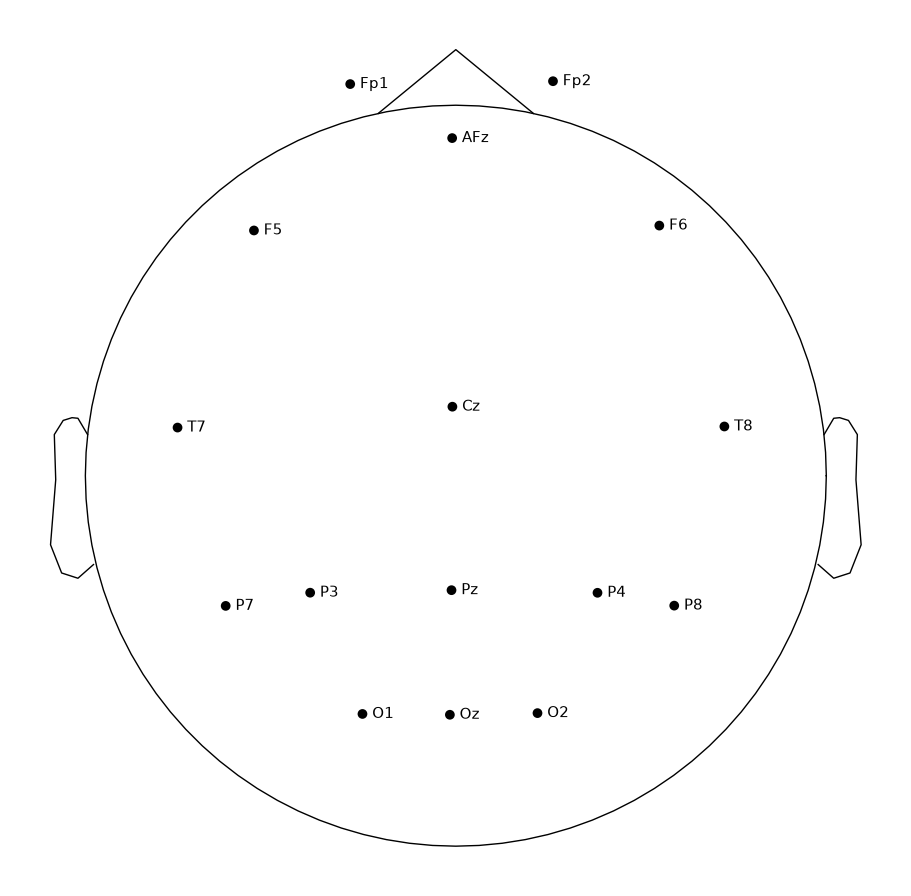

In [7]:
if example_raw.get_montage() is None:
    example_raw.set_montage('standard_1020')
fig = example_raw.plot_sensors(show_names=True, title=f'Sensor layout · subject {example_subject}')

Annotations: 480 flashes


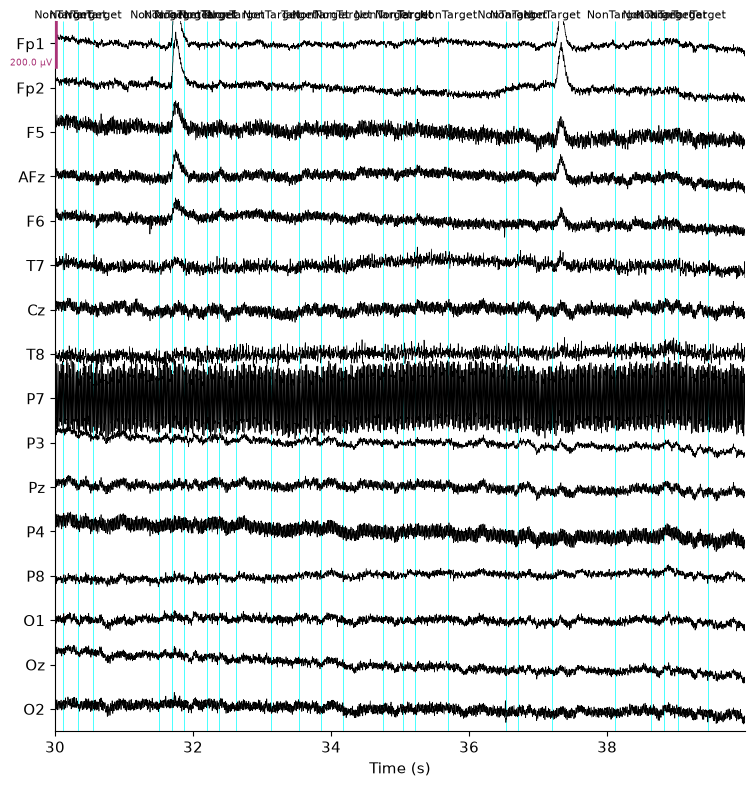

In [8]:
_, _, example_events = count_events(example_raw)
# Unfiltered data; the viewer only removes each channel's DC offset (remove_dc=True).
# MOABB also stores every flash as an annotation; we hide them and draw the events instead.
print('Annotations:', len(example_raw.annotations), 'flashes')
fig = (example_raw.copy().set_annotations(None)
       .plot(events=example_events, event_id=EVENT_ID, start=30, duration=10, n_channels=16,
             scalings=dict(eeg=100e-6), show_scrollbars=False, remove_dc=True,
             title=f'Raw EEG · subject {example_subject}, {example_cond}'))

**Audit interpretation.** The assertions above verify two training runs and 80/400
target/non-target flashes in every included subject. The raw and sensor figures show
the example subject. The per-run audit and QC tables retain all exceptions explicitly.

**Download optimization.** Only official meta.yml and training MAT ZIP members are
retrieved, using HTTP byte ranges and ZIP CRC checks. Local SHA-256 manifests record
the extracted bytes. MOABB's BI2013a reader still constructs all MNE Raw objects.
No EEG file parser or signal-processing loader was replaced. Earlier subjects already
cached by MOABB are reused. Download time depends on server/network conditions.


## 2 · Signal inspection and filter choice (notebook 03)
The starting point is the course's P300 contract from notebook 01,
`P300(fmin=0.5, fmax=20, resample=128)`. Each part of it has to earn its place on *this*
recording. We check four questions on the measured spectra:

1. Is a high-pass needed, and why 0.5 Hz rather than 0.1 or 1 Hz?
2. Is 20 Hz the right low-pass?
3. Does the 50 Hz mains noise found in the audit need a notch?
4. Is 128 Hz safe from aliasing and lossless for the P300 band?

**Rules that keep this stage leakage-free.**
* Every run is filtered on its own, never concatenated. The Within condition tests on a
  held-out run, so no filter support crosses from one run into another (notebook 03,
  "A reproducible filter report").
* The filter has no data-fitted parameters. The cut-offs were fixed before decoding and
  are never chosen by decoding score.

In [9]:
# Stage-2 configuration and helpers. Filter reporting follows notebook 03.
from scipy import signal

FILTER = dict(l_freq=0.5, h_freq=20.0, method='fir', phase='zero',
              fir_window='hamming', fir_design='firwin')
SFREQ_OUT = 128.0              # new Nyquist 64 Hz, far above the 25 Hz stop-band edge
EPOCH_WINDOW = (-0.1, 0.8)     # used from stage 4 on; needed here for the edge guard


def design_filter(sfreq, l_freq=FILTER['l_freq'], h_freq=FILTER['h_freq']):
    """FIR coefficients exactly as Raw.filter builds them (same window and design)."""
    return mne.filter.create_filter(None, sfreq, l_freq, h_freq, method='fir', phase='zero',
                                    fir_window=FILTER['fir_window'],
                                    fir_design=FILTER['fir_design'], verbose=False)


def half_length_s(h, sfreq):
    """Zero-phase FIR support on each side of a sample, in seconds."""
    return (len(h) - 1) / 2 / sfreq


def filter_resample(raw, l_freq=FILTER['l_freq'], h_freq=FILTER['h_freq'], sfreq_out=SFREQ_OUT):
    """Stage-2 preprocessing of ONE run: band-pass, then resample with the events.

    Returns (raw_out, events_out). The input `raw` is not modified.
    """
    _, _, events = count_events(raw)
    filt = raw.copy().filter(l_freq, h_freq, picks='eeg', method='fir', phase='zero',
                             fir_window=FILTER['fir_window'], fir_design=FILTER['fir_design'])
    return filt.resample(sfreq_out, events=events)


def edge_guard(events, sfreq, n_times, guard_s, window=EPOCH_WINDOW):
    """True for flashes whose epoch window stays guard_s away from both recording edges."""
    t = events[:, 0] / sfreq
    return (t + window[0] >= guard_s) & (t + window[1] <= n_times / sfreq - guard_s)


def welch(raw, n_fft):
    """Welch PSD of the EEG channels in V²/Hz (MNE removes each segment's DC)."""
    spec = raw.compute_psd(method='welch', picks='eeg', fmin=0, fmax=raw.info['sfreq'] / 2,
                           n_fft=n_fft)
    return spec.freqs, spec.get_data()


def band_rms_uV(freqs, psd, lo, hi):
    """RMS amplitude (µV) per channel in [lo, hi] Hz, by integrating the PSD."""
    sel = (freqs >= lo) & (freqs <= hi)
    return np.sqrt(psd[:, sel].sum(axis=1) * (freqs[1] - freqs[0])) * 1e6


h_main = design_filter(512.0)
GUARD_S = half_length_s(h_main, 512.0)
print(f'FIR: {len(h_main)} taps = {len(h_main) / 512:.2f} s, '
      f'support ±{GUARD_S:.2f} s around each sample')

FIR: 3381 taps = 6.60 s, support ±3.30 s around each sample


### 2.1 · Raw spectrum and the filter's response
The figure shows Welch PSDs before and after preprocessing, for the median channel and for
P7, the noisiest channel in the audit. The right panel shows the filter's own gain. Notebook
03 stresses that a data spectrum is not the filter response: it is the input spectrum
shaped by that response.

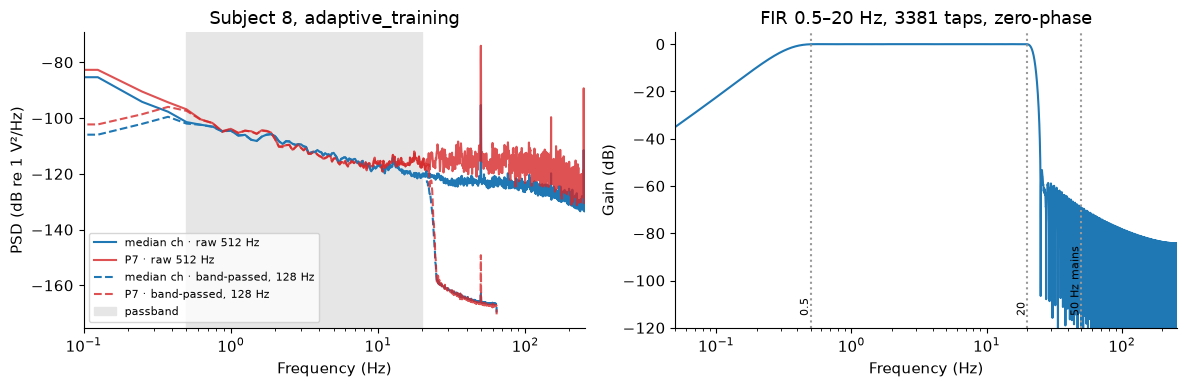

Filter report (notebook 03 checklist)
  family                           FIR, windowed design (firwin), Hamming window
  passband                         0.5–20.0 Hz
  -6 dB points                     0.25 Hz and 22.5 Hz (MNE auto transition bands 0.5 Hz / 5 Hz)
  length                           3381 taps = 6.60 s at 512 Hz
  phase                            zero-phase (non-causal, offline only)
  gain 0.1 / 1 / 10 / 25 / 50 Hz   -22.3 / 0.0 / -0.0 / -52.0 / -75.1 dB
  applied                          continuous data, each run separately, before epoching
  boundaries                       MNE 'reflect_limited' padding + edge guard of 3.30 s (2.3)
  resampling                       128 Hz after the low-pass; events resampled with the data


In [10]:
f_raw, p_raw = welch(example_raw, n_fft=4096)                 # 0.125 Hz resolution
example_out, example_events_out = filter_resample(example_raw)
f_out, p_out = welch(example_out, n_fft=1024)                 # same resolution at 128 Hz
i_p7 = example_raw.ch_names.index('P7')

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ax = axes[0]
for f, p, style, name in [(f_raw, p_raw, '-', 'raw 512 Hz'),
                          (f_out, p_out, '--', 'band-passed, 128 Hz')]:
    ax.plot(f, 10 * np.log10(np.median(p, axis=0)), style, color='C0', label=f'median ch · {name}')
    ax.plot(f, 10 * np.log10(p[i_p7]), style, color='C3', label=f'P7 · {name}', alpha=0.8)
ax.axvspan(FILTER['l_freq'], FILTER['h_freq'], color='0.9', zorder=0, label='passband')
ax.set(xscale='log', xlim=(0.1, 256), xlabel='Frequency (Hz)', ylabel='PSD (dB re 1 V²/Hz)',
       title=f'Subject {example_subject}, {example_cond}')
ax.legend(fontsize=8, loc='lower left')

w, H = signal.freqz(h_main, worN=2 ** 16, fs=512.0)
gain_db = 20 * np.log10(np.maximum(np.abs(H), 1e-10))
ax = axes[1]
ax.plot(w, gain_db)
for x, lab in [(FILTER['l_freq'], '0.5'), (FILTER['h_freq'], '20'), (50, '50 Hz mains')]:
    ax.axvline(x, color='0.6', ls=':')
    ax.text(x, -115, lab, rotation=90, va='bottom', ha='right', fontsize=8)
ax.set(xscale='log', xlim=(0.05, 256), ylim=(-120, 5), xlabel='Frequency (Hz)',
       ylabel='Gain (dB)', title=f'FIR 0.5–20 Hz, {len(h_main)} taps, zero-phase')
plt.tight_layout()
plt.show()


def gain_at(freq):
    return gain_db[np.argmin(np.abs(w - freq))]


print('Filter report (notebook 03 checklist)')
filter_report = {
    'family': 'FIR, windowed design (firwin), Hamming window',
    'passband': f"{FILTER['l_freq']}–{FILTER['h_freq']} Hz",
    '-6 dB points': '0.25 Hz and 22.5 Hz (MNE auto transition bands 0.5 Hz / 5 Hz)',
    'length': f'{len(h_main)} taps = {len(h_main) / 512:.2f} s at 512 Hz',
    'phase': 'zero-phase (non-causal, offline only)',
    'gain 0.1 / 1 / 10 / 25 / 50 Hz': ' / '.join(f'{gain_at(x):.1f}' for x in [0.1, 1, 10, 25, 50]) + ' dB',
    'applied': 'continuous data, each run separately, before epoching',
    'boundaries': f"MNE 'reflect_limited' padding + edge guard of {GUARD_S:.2f} s (2.3)",
    'resampling': f'{SFREQ_OUT:.0f} Hz after the low-pass; events resampled with the data',
}
for key, value in filter_report.items():
    print(f'  {key:<32} {value}')

### 2.2 · Per-run measurements behind each decision
These are measured on every audited run, so the full Colab run gives the numbers for all
17 subjects:

* **`drift_frac`** is the share of 0–20 Hz power that lies below 0.5 Hz. A large value is
  why we need a high-pass.
* **`mains_before_uV` and `mains_after_uV`** are the RMS amplitude in 49.5–50.5 Hz on the
  worst channel, before and after preprocessing.
* **`mains_resid_pct`** is the mains residue as a percentage of the in-band (1–20 Hz) RMS.
  If it is far below 1%, a notch would change nothing.
* **`resample_max_err_uV`** is the largest difference between the 128 Hz signal and every
  4th sample of the 512 Hz filtered signal. The 512 → 128 Hz step is lossless only if this
  is tiny next to `inband_rms_uV`.
* **`events_kept`** checks that resampling the events preserved the 80/400 counts.
* **`edge_dropped`** is the number of flashes whose epoch falls within the filter support
  of a recording edge (see 2.3).

In [11]:
def stage2_row(subject, run, condition, raw):
    f0, p0 = welch(raw, n_fft=4096)
    out, ev_out = filter_resample(raw)
    f1, p1 = welch(out, n_fft=1024)
    inband = band_rms_uV(f1, p1, 1, 20)
    mains0, mains1 = band_rms_uV(f0, p0, 49.5, 50.5), band_rms_uV(f1, p1, 49.5, 50.5)
    # Lossless resampling check: compare with the 512 Hz filtered data at the same instants.
    ref = raw.copy().filter(picks='eeg', **FILTER).get_data(picks='eeg')[:, ::4]
    new = out.get_data(picks='eeg')
    n = min(ref.shape[1], new.shape[1]) - 64                  # skip resampling edge samples
    err = np.abs(new[:, 64:n] - ref[:, 64:n]).max() * 1e6
    keep = edge_guard(ev_out, out.info['sfreq'], out.n_times, GUARD_S)
    counts_out = {name: int((ev_out[:, 2] == code).sum()) for name, code in EVENT_ID.items()}
    return {
        'subject': subject, 'run': run, 'condition': condition,
        'drift_frac': round(float(np.median(p0[:, f0 < 0.5].sum(1) / p0[:, f0 <= 20].sum(1))), 2),
        'mains_ch': raw.ch_names[int(np.argmax(mains0))],
        'mains_before_uV': round(float(mains0.max()), 2),
        'mains_after_uV': round(float(mains1.max()), 4),
        'mains_resid_pct': round(float(np.max(mains1 / inband)) * 100, 3),
        'inband_rms_uV': round(float(np.median(inband)), 2),
        'resample_max_err_uV': round(float(err), 3),
        'events_kept': counts_out == {'Target': 80, 'NonTarget': 400},
        'edge_dropped_T': int((~keep & (ev_out[:, 2] == EVENT_ID['Target'])).sum()),
        'edge_dropped_NT': int((~keep & (ev_out[:, 2] == EVENT_ID['NonTarget'])).sum()),
    }


stage2 = pd.DataFrame([stage2_row(s, run, cond, raw)
                       for s, runs in raws_by_subject.items() for _, run, cond, raw in runs])
print(stage2.to_string(index=False))
assert stage2['events_kept'].all(), 'resampling changed the event counts'

 subject run            condition  drift_frac mains_ch  mains_before_uV  mains_after_uV  mains_resid_pct  inband_rms_uV  resample_max_err_uV  events_kept  edge_dropped_T  edge_dropped_NT
       8   0    adaptive_training        0.80       P7            82.93          0.0299            0.155           8.83                0.042         True               0                0
       8   2 nonadaptive_training        0.73       P7            60.80          0.0111            0.113           8.83                0.034         True               1                2
       9   0    adaptive_training        0.72       T8            12.14          0.0406            0.155          12.60                0.076         True               0                0
       9   2 nonadaptive_training        0.70       P7            14.68          0.0065            0.064           7.21                0.008         True               0                0
      10   0    adaptive_training        0.62       P7           

### 2.3 · Recording edges: how close to an edge is still safe?
A zero-phase FIR needs samples on both sides. Near the start or end of a recording, MNE pads
the missing side by reflection, and the output there is distorted. Some runs end only about
2 s after the last flash, so we measure this instead of assuming it.

The test: we cut the example run at 200 s, filter both the cut and the full version, and
compare them before the cut. The full version is the reference, because there it has real
data on both sides.

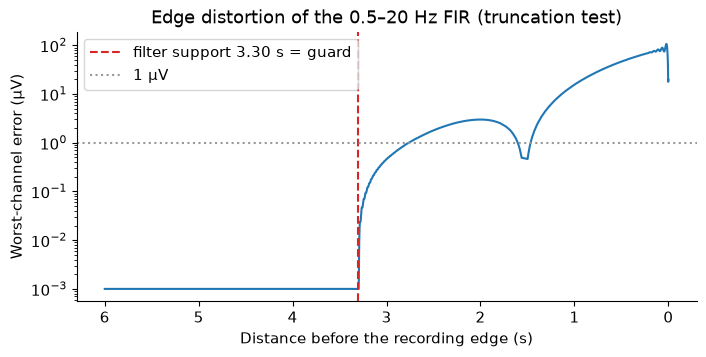

 high-pass (Hz)  guard (s)  flashes lost to edges (all audited runs)
            0.1      16.50                                       302
            0.5       3.30                                        15
            1.0       1.65                                         5


In [12]:
CUT_S = 200.0
full = example_raw.copy().filter(picks='eeg', **FILTER).get_data(picks='eeg')
cut = example_raw.copy().crop(0, CUT_S).filter(picks='eeg', **FILTER).get_data(picks='eeg')
n_cut = cut.shape[1]
edge_err = np.abs(cut - full[:, :n_cut]).max(axis=0) * 1e6       # worst channel, µV
dist_s = (n_cut - 1 - np.arange(n_cut)) / 512.0
show = dist_s <= 6

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.semilogy(dist_s[show], np.maximum(edge_err[show], 1e-3))
ax.axvline(GUARD_S, color='C3', ls='--', label=f'filter support {GUARD_S:.2f} s = guard')
ax.axhline(1.0, color='0.6', ls=':', label='1 µV')
ax.invert_xaxis()
ax.set(xlabel='Distance before the recording edge (s)', ylabel='Worst-channel error (µV)',
       title='Edge distortion of the 0.5–20 Hz FIR (truncation test)')
ax.legend()
plt.show()

# How many flashes would each high-pass cut-off lose to its own edge guard?
hp_rows = []
for l_freq in [0.1, 0.5, 1.0]:
    g = half_length_s(design_filter(512.0, l_freq=l_freq), 512.0)
    lost = sum(int((~edge_guard(count_events(raw)[2], 512.0, raw.n_times, g)).sum())
               for runs in raws_by_subject.values() for *_, raw in runs)
    hp_rows.append({'high-pass (Hz)': l_freq, 'guard (s)': round(g, 2),
                    'flashes lost to edges (all audited runs)': lost})
print(pd.DataFrame(hp_rows).to_string(index=False))

### 2.4 · Is the passband right for the P300?
We test each edge of the band on the example subject, using the target − non-target
difference at Pz:

* **High-pass.** A high-pass can shrink a slow, positive component such as the P300. We
  compare 0.1, 0.5, 1 and 2 Hz with the low-pass fixed at 20 Hz.
* **Low-pass.** We compare 20 and 30 Hz with the high-pass fixed at 0.5 Hz. If the
  20–30 Hz band carried ERP information, the two waves would differ in a systematic way.

**One factor at a time.** Every curve uses the *same* flashes: one common edge guard taken
from the longest filter (0.1 Hz, ±16.5 s). As in the pipeline, the curves carry no
baseline correction (see 3.3).

**What the zero level is matters.** We report each peak two ways:
* measured from 0 µV;
* measured from the −100–0 ms mean.

Neither reference is clean. With no baseline, slow offsets left by gentle high-passes stay
in the wave. The pre-flash window is not neutral either: 3.3 shows that it holds a target's
response before about 20% of non-targets but before almost no targets. The truth for the
P300 amplitude lies somewhere between the two columns.

The band **0.5–20 Hz was fixed beforehand** from the course contract. These checks only
confirm that it does not distort the waveform. We do **not** pick the band that maximises
the class difference, because that would be tuning on labels.

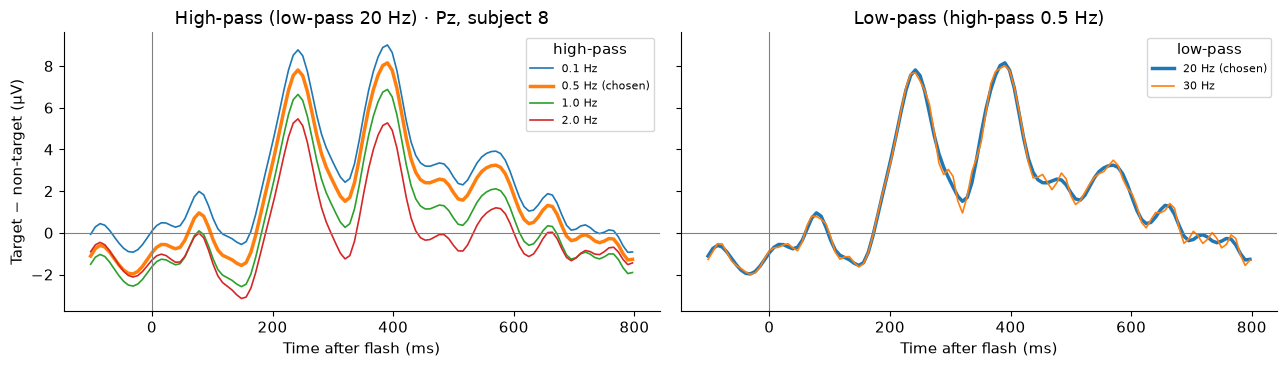

 high-pass (Hz)  flashes  peak from 0 (µV)  peak from pre-flash (µV)  latency (ms)  peak from 0 % of 0.1 Hz  peak from pre-flash % of 0.1 Hz
            0.1      926              9.01                      9.29           391                    100.0                            100.0
            0.5      926              8.15                      9.48           391                     90.0                            102.0
            1.0      926              6.87                      8.72           391                     76.0                             94.0
            2.0      926              5.47                      6.82           242                     61.0                             73.0

20 vs 30 Hz low-pass: RMS of the difference between the two waves = 0.21 µV, against an RMS of 3.13 µV for the 20 Hz wave itself.


In [13]:
HP_CANDIDATES = [0.1, 0.5, 1.0, 2.0]
GUARD_COMMON = max(half_length_s(design_filter(512.0, l_freq=l), 512.0) for l in HP_CANDIDATES)


def pz_difference(runs, l_freq, h_freq=FILTER['h_freq'], guard_s=GUARD_COMMON):
    """Target − non-target average at Pz (µV), both runs pooled, same flashes for every band."""
    diffs, n_kept = [], 0
    for *_, raw in runs:
        out, ev = filter_resample(raw, l_freq=l_freq, h_freq=h_freq)
        ev = ev[edge_guard(ev, out.info['sfreq'], out.n_times, guard_s)]
        n_kept += len(ev)
        ep = mne.Epochs(out, ev, EVENT_ID, *EPOCH_WINDOW, baseline=None, picks=['Pz'],
                        preload=True, verbose=False)
        diffs.append(ep['Target'].average().data[0] - ep['NonTarget'].average().data[0])
    return ep.times, np.mean(diffs, axis=0) * 1e6, n_kept


def peak_in_window(t, wave, lo=0.2, hi=0.6):
    """Peak in [lo, hi] s: (from 0 µV, from the −100–0 ms mean, latency ms)."""
    win = (t >= lo) & (t <= hi)
    i = np.argmax(wave[win])
    return wave[win][i], wave[win][i] - wave[t < 0].mean(), int(round(t[win][i] * 1e3))


runs_example = raws_by_subject[example_subject]
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
peak_rows = []
for l_freq in HP_CANDIDATES:
    t, dw, n_kept = pz_difference(runs_example, l_freq)
    from_zero, from_pre, lat = peak_in_window(t, dw)
    chosen = l_freq == FILTER['l_freq']
    axes[0].plot(t * 1e3, dw, lw=2.5 if chosen else 1.2,
                 label=f'{l_freq} Hz' + (' (chosen)' if chosen else ''))
    peak_rows.append({'high-pass (Hz)': l_freq, 'flashes': n_kept,
                      'peak from 0 (µV)': round(from_zero, 2),
                      'peak from pre-flash (µV)': round(from_pre, 2), 'latency (ms)': lat})
axes[0].set(title=f'High-pass (low-pass 20 Hz) · Pz, subject {example_subject}',
            xlabel='Time after flash (ms)', ylabel='Target − non-target (µV)')
axes[0].legend(title='high-pass', fontsize=8)

lp_waves = {}
for h_freq in [20.0, 30.0]:
    t, dw, n_kept = pz_difference(runs_example, FILTER['l_freq'], h_freq=h_freq)
    lp_waves[h_freq] = dw
    axes[1].plot(t * 1e3, lp_waves[h_freq], lw=2.5 if h_freq == FILTER['h_freq'] else 1.2,
                 label=f'{h_freq:.0f} Hz' + (' (chosen)' if h_freq == FILTER['h_freq'] else ''))
axes[1].set(title='Low-pass (high-pass 0.5 Hz)', xlabel='Time after flash (ms)')
axes[1].legend(title='low-pass', fontsize=8)
for ax in axes:
    ax.axhline(0, color='0.5', lw=0.8)
    ax.axvline(0, color='0.5', lw=0.8)
plt.tight_layout()
plt.show()

peaks = pd.DataFrame(peak_rows)
for col in ['peak from 0 (µV)', 'peak from pre-flash (µV)']:
    peaks[col.split(' (')[0] + ' % of 0.1 Hz'] = (100 * peaks[col] / peaks[col].iloc[0]).round(0)
print(peaks.to_string(index=False))
extra = lp_waves[30.0] - lp_waves[20.0]
print(f'\n20 vs 30 Hz low-pass: RMS of the difference between the two waves = '
      f'{np.sqrt(np.mean(extra ** 2)):.2f} µV, against an RMS of {np.sqrt(np.mean(lp_waves[20.0] ** 2)):.2f} µV '
      f'for the 20 Hz wave itself.')

### Stage 2 decisions
The numbers quoted below come from the local smoke test on subject 8. The table in 2.2
gives them for every subject in the full run.

| Decision | Evidence |
|---|---|
| **High-pass 0.5 Hz** (−6 dB at 0.25 Hz) | 73–80% of the 0–20 Hz power lies below 0.5 Hz (`drift_frac`). Without a high-pass, drift dominates every epoch. The 0.1 Hz alternative needs a 33 s filter, and its ±16.5 s edge guard costs 34 flashes on subject 8, against 3 at 0.5 Hz (2.3). In 2.4 every cut-off uses the same 926 flashes. Relative to 0.1 Hz, the 0.5 Hz peak keeps 90% measured from 0 µV and 102% measured from the pre-flash mean, at the same latency (391 ms). So the loss is between 0 and about 10%, depending on the reference. At 1 Hz it keeps 76–94%. At 2 Hz it keeps 61–73%, the largest peak moves to the earlier component (242 ms), and undershoots appear. |
| **Low-pass 20 Hz** (−6 dB at 22.5 Hz, −52 dB at 25 Hz) | The course P300 contract (notebooks 01–02) uses 20 Hz. In 2.4, moving the low-pass to 30 Hz changes the difference wave by 0.21 µV RMS, about 7% of the wave's own RMS (3.13 µV), and adds only small ripples. The 20–30 Hz band therefore carries almost no ERP information here. Cutting it also removes the out-of-band P7 noise seen in 2.1. |
| **FIR rather than IIR** | Notebook 03: a symmetric FIR has linear phase, and applied zero-phase it leaves ERP latencies unchanged. A windowed FIR design is also always stable. An IIR reaches a sharp response with fewer coefficients, but its phase is non-linear unless filtered forward–backward, and it needs care to stay numerically stable. The FIR's cost is its length (6.6 s), which the edge guard handles. |
| **No notch filter** | The 50 Hz noise on P7 drops from ≈61–83 µV RMS to ≈0.01–0.03 µV, at most 0.16% of the in-band RMS (`mains_resid_pct`). The low-pass already gives −75 dB at 50 Hz, so a notch would add nothing (notebook 03, Practice 3). |
| **Resample to 128 Hz** | The new Nyquist is 64 Hz, far above the 25 Hz stop band, so nothing can alias. The largest difference from the 512 Hz signal is ≈0.04 µV, against an in-band RMS of ≈9 µV. The 80/400 event counts survive, and event timing moves by at most 1/256 s (3.9 ms). The 4× fewer samples make ICA in stage 3 cheaper. |
| **Edge guard ±3.30 s** | In the truncation test the error exceeds 1 µV only within about 2.8 s of an edge. Stage 5 drops any flash whose epoch lies within the filter support of an edge, and reports the count (`edge_dropped_*`: 3 of 960 flashes on subject 8). |

**P7.** Its high-frequency noise lies entirely outside the passband. Its in-band SD was
normal in the audit, so it is **not** marked bad on spectral grounds. Stage 3 re-checks it
after filtering.

**Limitation.** The zero-phase filter needs future samples, so it suits only this offline
study. A causal linear-phase FIR of the same length would delay the signal by 3.3 s; an
online BCI would need a causal IIR or minimum-phase design and would see a different
waveform.

## 3 · Artifact handling (notebook 04) and quality control (notebook 05)
The audit found blinks on the frontal channels. There are no EOG channels, so **Fp1 and
Fp2 serve as ocular proxies**: they are the scalp sites closest to the eyes and carry the
largest blink deflections. This is a declared approximation, not a measured EOG.

**Order of operations, per run (no data crosses runs):**

1. **Flat-channel check** on the stage-2 data. A flat channel is marked bad and kept out of
   the ICA fit.
2. **ICA**, configured as in notebook 04: FastICA, 15 components, `random_state=SEED`,
   `max_iter=1000`. It is fitted on a **1–20 Hz copy at 128 Hz**, because a 1 Hz high-pass
   stabilises ICA. The unmixing is then applied to the 0.5–20 Hz data, which has the same
   channels and reference.
3. **Component exclusion needs two independent kinds of evidence** (notebook 04: never
   remove a component by its index or its variance):
   * its time course is an outlier in correlation with Fp1/Fp2 (MNE `find_bads_eog`,
     z ≥ 3);
   * its scalp map is frontal: at least 50% of the map's power sits on Fp1, Fp2 and AFz.
4. **Noisy-channel check** after ICA. A non-proxy channel is marked bad if its SD is more
   than 3× or less than ⅓× the median SD of the 14 non-proxy channels, which is ≥9× off in
   power. A bad channel is marked bad and ignored by amplitude rejection. The decoder
   uses a fixed five-site physiological montage. A flagged core site stops analysis
   for review; pooled channel flags never change the training feature set.
   Interpolation is mentioned in notebook 04 but never demonstrated in notebooks 00–06, so
   we avoid it. A run with more than 2 bad channels is flagged for manual review.
   *Why a ratio rather than a robust z-score?* On subject 8 the 14 channels are so alike
   that the MAD is tiny. A robust z-score then flagged P7 and F6 at z ≈ 3.5, although their
   SD was only 1.3× the median. The ratio rule only fires for real outliers.
5. **Epochs** from −100 to 800 ms with **no baseline correction** (see 3.3). First the
   edge guard from stage 2 is applied, then a **peak-to-peak rejection at 100 µV** on any
   EEG channel (see 3.4). The two kinds of drop are counted separately, by class
   (notebook 05).

**Reference.** We keep the recorded left-earlobe reference. Notebook 04 shows that a common
average spreads any large artifact into every channel. With 16 sparse channels, two of them
blink-dominated proxies, the average is a poor estimate of zero. The one-sided earlobe
reference may add a small lateral asymmetry; we state this as a limitation.

**Leakage.** ICA, channel checks and thresholds use no labels. Each run is cleaned only with
its own data, so the held-out run in the Within condition never shapes the cleaning of the
training run. All thresholds are fixed here, before any decoding. Labels appear in this
stage only in *descriptive* checks (3.2 and 3.3), never in a choice.

In [14]:
ICA_PARAMS = dict(n_components=15, method='fastica', random_state=SEED, max_iter=1000)  # notebook 04
ICA_FIT_BAND = (1.0, 20.0)
EOG_PROXIES = ['Fp1', 'Fp2']
EOG_Z = 3.0
FRONTAL = ['Fp1', 'Fp2', 'AFz']
FRONTAL_MIN = 0.5
FLAT_UV = 0.5
BAD_RATIO = 3.0
MAX_BAD = 2
REJECT_P2P_UV = 100.0
BASELINE = None


def fit_ica(raw, main, bads):
    """Fit ICA on a 1–20 Hz, 128 Hz copy of one run; return (ica, evidence table, excluded)."""
    fit = raw.copy().filter(*ICA_FIT_BAND, picks='eeg', method='fir', phase='zero',
                            fir_window=FILTER['fir_window'], fir_design=FILTER['fir_design'])
    fit.resample(SFREQ_OUT)
    fit.info['bads'] = list(bads)
    params = dict(ICA_PARAMS)
    params['n_components'] = min(params['n_components'], len(mne.pick_types(fit.info, eeg=True, exclude='bads')) - 1)
    ica = mne.preprocessing.ICA(**params).fit(fit, picks='eeg')
    eog_idx, scores = ica.find_bads_eog(fit, ch_name=EOG_PROXIES, threshold=EOG_Z,
                                        measure='zscore')
    maps = ica.get_components()
    names = [ch for ch in fit.copy().pick('eeg', exclude='bads').ch_names]
    rows = [r for r, ch in enumerate(names) if ch in FRONTAL]
    frontal = (maps[rows] ** 2).sum(0) / (maps ** 2).sum(0)
    evidence = pd.DataFrame({
        'component': np.arange(ica.n_components_),
        **{f'r_{ch}': np.round(s, 2) for ch, s in zip(EOG_PROXIES, scores)},
        'eog_outlier': np.isin(np.arange(ica.n_components_), eog_idx),
        'frontal_frac': np.round(frontal, 2),
    })
    evidence['excluded'] = evidence['eog_outlier'] & (evidence['frontal_frac'] >= FRONTAL_MIN)
    excluded = evidence.loc[evidence['excluded'], 'component'].tolist()
    return ica, evidence, excluded, fit


def concat_epochs(epochs_list):
    """Concatenate runs whose bad-channel lists differ: all copies get the union of bads."""
    bads = sorted({ch for ep in epochs_list for ch in ep.info['bads']})
    copies = []
    for ep in epochs_list:
        ep = ep.copy()
        ep.info['bads'] = list(bads)
        copies.append(ep)
    return mne.concatenate_epochs(copies, verbose=False)


def blink_onsets_s(raw):
    """Blink times (s) detected on the ocular proxies (MNE find_eog_events)."""
    blinks = mne.preprocessing.find_eog_events(raw, ch_name=EOG_PROXIES, verbose=False)
    return blinks[:, 0] / raw.info['sfreq']


def clean_run(subject, run, condition, raw):
    """Stage 2 + stage 3 for ONE run. Returns a dict with clean data, epochs and a QC row."""
    main, events = filter_resample(raw)
    sd = main.get_data(picks='eeg').std(axis=1) * 1e6
    eeg_names = [main.ch_names[i] for i in mne.pick_types(main.info, eeg=True)]
    flat = [ch for ch, s in zip(eeg_names, sd) if s < FLAT_UV]

    ica, evidence, excluded, fit = fit_ica(raw, main, flat)
    var_removed = (ica.get_explained_variance_ratio(fit, components=excluded, ch_type='eeg')['eeg']
                   if excluded else 0.0)
    clean = main.copy()
    clean.info['bads'] = list(flat)
    ica.apply(clean, exclude=excluded)

    good = [ch for ch in eeg_names if ch not in EOG_PROXIES and ch not in flat]
    sd_clean = clean.get_data(picks=good).std(axis=1)
    ratio = sd_clean / np.median(sd_clean)
    noisy = [ch for ch, r in zip(good, ratio) if r > BAD_RATIO or r < 1 / BAD_RATIO]
    bads = flat + noisy
    review = len(bads) > MAX_BAD
    clean.info['bads'] = bads          # kept in the data; rejection ignores bad channels

    # Descriptive: blinks inside epoch windows, by class (before cleaning).
    t_blink = blink_onsets_s(main)
    t_flash = events[:, 0] / SFREQ_OUT
    has_blink = np.array([np.any((t_blink >= t + EPOCH_WINDOW[0]) & (t_blink <= t + EPOCH_WINDOW[1]))
                          for t in t_flash])
    is_target = events[:, 2] == EVENT_ID['Target']

    metadata = pd.DataFrame({'subject': subject, 'run': run, 'condition': condition,
                             'flash': np.arange(len(events)),
                             'label': np.where(is_target, 'Target', 'NonTarget'),
                             'blink': has_blink})
    keep = edge_guard(events, SFREQ_OUT, clean.n_times, GUARD_S)
    epochs = mne.Epochs(clean, events[keep], EVENT_ID, *EPOCH_WINDOW, baseline=BASELINE,
                        picks=eeg_names, metadata=metadata[keep].reset_index(drop=True),
                        preload=True, verbose=False)   # all 16 channels in every run
    n_before = {lab: int((epochs.metadata['label'] == lab).sum()) for lab in EVENT_ID}
    epochs.drop_bad(reject={'eeg': REJECT_P2P_UV * 1e-6}, verbose=False)
    n_after = {lab: int((epochs.metadata['label'] == lab).sum()) for lab in EVENT_ID}

    qc = {
        'subject': subject, 'run': run, 'condition': condition,
        'bad_channels': ','.join(bads) or '-', 'review': review,
        'max_sd_ratio': f'{ratio.max():.2f} ({good[int(np.argmax(ratio))]})',
        'ica_excluded': ','.join(map(str, excluded)) or '-',
        'ica_var_removed': round(float(var_removed), 2),
        'blinks_per_min': round(len(t_blink) / (clean.times[-1] / 60), 1),
        'blink_frac_T': round(float(has_blink[is_target].mean()), 3),
        'blink_frac_NT': round(float(has_blink[~is_target].mean()), 3),
        'edge_drop_T': int((~keep & is_target).sum()), 'edge_drop_NT': int((~keep & ~is_target).sum()),
        'amp_drop_T': n_before['Target'] - n_after['Target'],
        'amp_drop_NT': n_before['NonTarget'] - n_after['NonTarget'],
        'kept_T': n_after['Target'], 'kept_NT': n_after['NonTarget'],
    }
    return dict(main=main, clean=clean, events=events, ica=ica, evidence=evidence,
                excluded=excluded, epochs=epochs, qc=qc)


t0 = time.perf_counter()
cleaned = {(s, run): clean_run(s, run, cond, raw)
           for s, runs in raws_by_subject.items() for _, run, cond, raw in runs}
qc = pd.DataFrame([c['qc'] for c in cleaned.values()])
print(f'Stage 3 for {len(cleaned)} runs: {time.perf_counter() - t0:.1f} s\n')
print(qc.to_string(index=False))
assert not qc['review'].any(), 'a run needs manual channel review (see bad_channels)'
GLOBAL_BADS = sorted({ch for c in cleaned.values() for ch in c['clean'].info['bads']})
print('\nBad channels observed across runs (QC only, never used to select training features):', GLOBAL_BADS or 'none')
CORE_P300 = ['Cz', 'Pz', 'P3', 'P4', 'Oz']
# Dropping a core P300 site for all 17 subjects because of one run is a decision for a person,
# not for this rule. If either assert fires, keep it and send the message back for review.
assert not set(GLOBAL_BADS) & set(CORE_P300), f'core P300 channel flagged bad: {GLOBAL_BADS}'
# Non-core bad channels remain excluded from epoch rejection; the decoder uses a fixed montage.

Stage 3 for 34 runs: 63.3 s

 subject run            condition bad_channels  review max_sd_ratio ica_excluded  ica_var_removed  blinks_per_min  blink_frac_T  blink_frac_NT  edge_drop_T  edge_drop_NT  amp_drop_T  amp_drop_NT  kept_T  kept_NT
       8   0    adaptive_training            -   False    1.30 (P7)          0,1             0.77            17.9         0.175          0.117            0             0           1            1      79      399
       8   2 nonadaptive_training            -   False    1.19 (P7)            0             0.78            17.5         0.325          0.185            1             2           0            2      79      396
       9   0    adaptive_training           F6   False    3.53 (F6)            0             0.24             8.5         0.013          0.025            0             0           0            1      80      399
       9   2 nonadaptive_training            -   False    1.44 (Cz)            0             0.45             4.2         0

### 3.1 · Evidence for the excluded components (example run)
The table lists each component's correlation with the proxies, whether MNE flags it as an
outlier, and the frontal share of its map. Next come the scalp maps (excluded components are
named in the printout). The last plot shows the average blink before and after removal, which
is "what ICA removed" (notebook 04).

 component  r_Fp1  r_Fp2  eog_outlier  frontal_frac  excluded
         0   0.94   0.81         True          0.83      True
         1  -0.29  -0.55         True          0.95      True
         2  -0.06  -0.03        False          0.02     False
         3  -0.07  -0.18        False          0.62     False
         4   0.11   0.07        False          0.26     False
         5   0.08   0.08        False          0.07     False
         6   0.07  -0.08        False          0.89     False
         7  -0.01   0.08        False          0.30     False
         8  -0.05  -0.06        False          0.12     False
         9  -0.06  -0.07        False          0.06     False
        10   0.01   0.01        False          0.19     False
        11   0.04   0.04        False          0.09     False
        12  -0.05  -0.04        False          0.05     False
        13  -0.03  -0.03        False          0.02     False
        14   0.02   0.03        False          0.02     False
Excluded

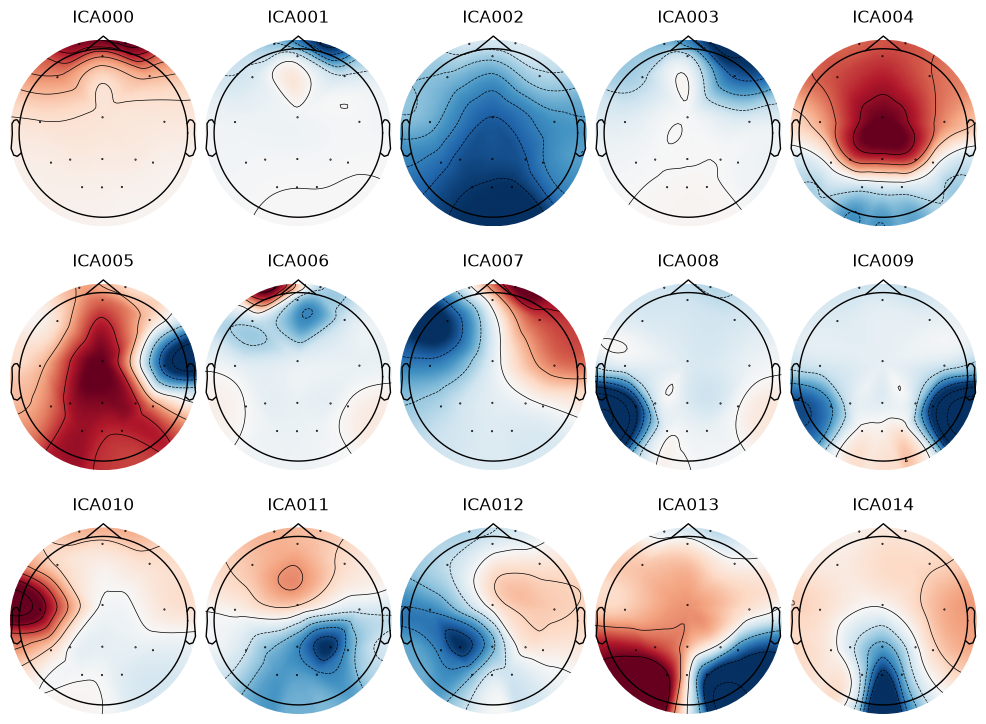

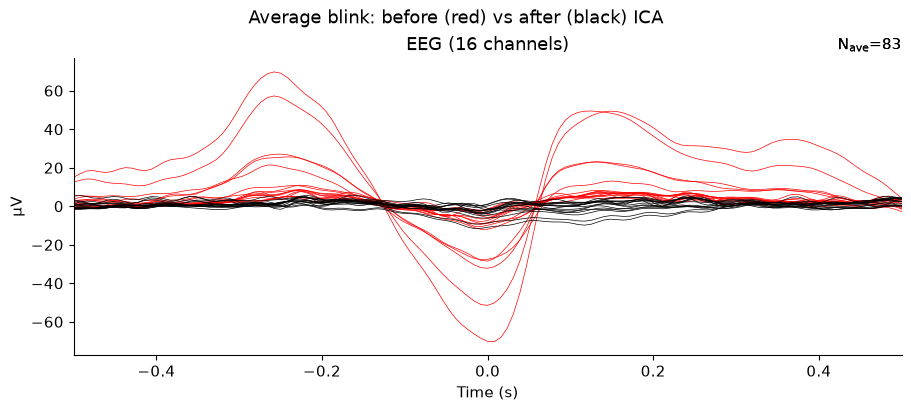

In [15]:
ex = cleaned[(example_subject, example_run)]
print(ex['evidence'].to_string(index=False))
print('Excluded:', ex['excluded'])
fig = ex['ica'].plot_components(title=f'ICA maps · subject {example_subject}, {example_cond}',
                                show=False)
plt.show()

blink_evoked = mne.preprocessing.create_eog_epochs(ex['main'], ch_name=EOG_PROXIES,
                                                   verbose=False).average()
fig = ex['ica'].plot_overlay(blink_evoked, exclude=ex['excluded'], picks='eeg',
                             title='Average blink: before (red) vs after (black) ICA', show=False)
plt.show()

### 3.2 · Eye activity is a confound here, and ICA removes it without removing the P300
If blinks are time-locked to targets, an uncleaned decoder could detect targets from the
eyes rather than from the brain. The QC table above already counts this (`blink_frac_T`
versus `blink_frac_NT`). Below, the target − non-target difference at Fp1 (ocular) and Pz
(P300) is shown before and after ICA. This is a descriptive check of the cleaning; it chooses
nothing.

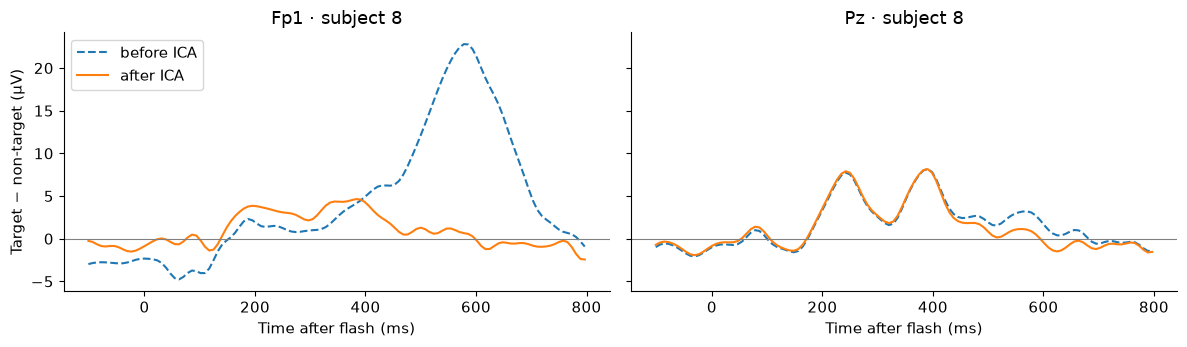

channel       data  T−NT max 200–600 ms (µV)
    Fp1 before ICA                     22.80
    Fp1  after ICA                      4.64
     Pz before ICA                      8.16
     Pz  after ICA                      8.16

Blink fraction T vs NT across 17 subjects: median T 0.043, NT 0.039, Wilcoxon p = 0.0151


In [16]:
def difference_wave(raw, events, ch):
    keep = edge_guard(events, SFREQ_OUT, raw.n_times, GUARD_S)
    ep = mne.Epochs(raw, events[keep], EVENT_ID, *EPOCH_WINDOW, baseline=None, picks=[ch],
                    preload=True, verbose=False)
    return ep.times, (ep['Target'].average().data[0] - ep['NonTarget'].average().data[0]) * 1e6


runs_ex = [cleaned[k] for k in cleaned if k[0] == example_subject]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), sharey=True)
conf_rows = []
for ax, ch in zip(axes, ['Fp1', 'Pz']):
    for key, style in [('main', '--'), ('clean', '-')]:
        waves = [difference_wave(c[key], c['events'], ch) for c in runs_ex]
        t, dw = waves[0][0], np.mean([w[1] for w in waves], axis=0)
        ax.plot(t * 1e3, dw, style, label='before ICA' if key == 'main' else 'after ICA')
        win = (t >= 0.2) & (t <= 0.6)
        conf_rows.append({'channel': ch, 'data': 'before ICA' if key == 'main' else 'after ICA',
                          'T−NT max 200–600 ms (µV)': round(dw[win].max(), 2)})
    ax.axhline(0, color='0.5', lw=0.8)
    ax.set(title=f'{ch} · subject {example_subject}', xlabel='Time after flash (ms)')
axes[0].set_ylabel('Target − non-target (µV)')
axes[0].legend()
plt.tight_layout()
plt.show()
print(pd.DataFrame(conf_rows).to_string(index=False))

# Group-level test of the blink confound (needs several subjects; run on Colab).
blink_subj = qc.groupby('subject')[['blink_frac_T', 'blink_frac_NT']].mean()
if len(blink_subj) >= MIN_GROUP_N:
    from scipy.stats import wilcoxon
    stat = wilcoxon(blink_subj['blink_frac_T'], blink_subj['blink_frac_NT'])
    print(f'\nBlink fraction T vs NT across {len(blink_subj)} subjects: '
          f'median T {blink_subj.blink_frac_T.median():.3f}, NT {blink_subj.blink_frac_NT.median():.3f}, '
          f'Wilcoxon p = {stat.pvalue:.4f}')
else:
    print(f'\nOnly {len(blink_subj)} subject(s) audited: the group blink test runs on the full set.')

### 3.3 · Why there is no baseline correction
Notebook 05 warns that a baseline is only fair if the pre-event interval is neutral and equal
across conditions. In Brain Invaders the flashes are dense: the median interval is about
350–400 ms, shorter than one epoch. The −100–0 ms window of a flash therefore falls 250–400 ms
after the previous flash, inside that flash's P300 window. The table shows how often the
previous flash was a target, for each class.

In [17]:
prev_rows = []
for (s, run), c in cleaned.items():
    is_t = c['events'][:, 2] == EVENT_ID['Target']
    prev_t = np.r_[False, is_t[:-1]]
    soa_ms = np.diff(c['events'][:, 0]) / SFREQ_OUT * 1e3
    prev_rows.append({'subject': s, 'run': run,
                      'P(prev=Target | Target)': round(prev_t[is_t].mean(), 3),
                      'P(prev=Target | NonTarget)': round(prev_t[~is_t].mean(), 3),
                      'interval p5/p50/p95 (ms)': '/'.join(f'{v:.0f}' for v in np.percentile(soa_ms, [5, 50, 95]))})
print(pd.DataFrame(prev_rows).to_string(index=False))

 subject run  P(prev=Target | Target)  P(prev=Target | NonTarget) interval p5/p50/p95 (ms)
       8   0                    0.012                       0.198             180/398/1023
       8   2                    0.038                       0.192              180/352/985
       9   0                    0.012                       0.198             187/406/1002
       9   2                    0.025                       0.195             180/430/1031
      10   0                    0.012                       0.198             180/383/1000
      10   2                    0.038                       0.192             179/375/1000
      11   0                    0.038                       0.192             180/359/1024
      11   2                    0.038                       0.192             180/375/1000
      12   0                    0.050                       0.190             180/398/1002
      12   2                    0.025                       0.192             180/406/1000

The previous flash is a target before roughly one non-target in five but almost never before
a target, so the two classes would get **systematically different baselines**. Subtracting
them would add a class-dependent offset that is not part of the response to the current
flash. We therefore use no baseline. Stage 2's 0.5 Hz high-pass already removes the slow
offsets a baseline would otherwise handle.

### 3.4 · Rejection threshold: sensitivity by class
After ICA, peak-to-peak amplitudes are far smaller. The threshold of **100 µV** is meant to
catch only gross residual artifacts. The curve shows the retained fraction for each class
over a range of thresholds (notebook 05, Practice 4) on the same candidate epochs. Unequal
curves would signal a selection effect.

/tmp/ipykernel_8539/1314788063.py:48: RuntimeWarning: Concatenation of Annotations within Epochs is not supported yet. All annotations will be dropped.
  return mne.concatenate_epochs(copies, verbose=False)


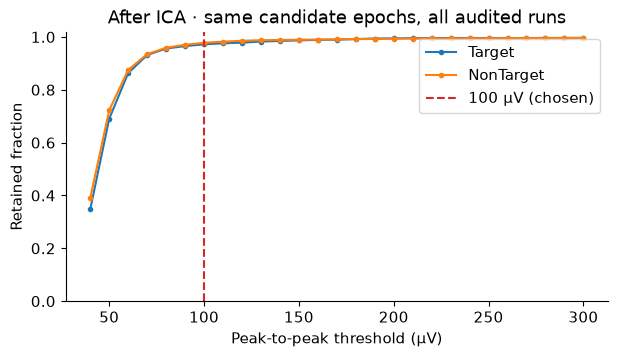

Epoch max peak-to-peak after ICA (µV): p50 / p90 / p99 / max = 43 / 63 / 159 / 1642


/tmp/ipykernel_8539/1314788063.py:48: RuntimeWarning: Concatenation of Annotations within Epochs is not supported yet. All annotations will be dropped.
  return mne.concatenate_epochs(copies, verbose=False)


before ICA: 1648 of 16305 epochs exceed 100 µV (Target 14.2%, NonTarget 9.3%)
 after ICA: 377 of 16305 epochs exceed 100 µV (Target 2.8%, NonTarget 2.2%)


In [18]:
def candidate_epochs(key):
    """Edge-guarded, unrejected epochs of every run on all 16 channels (bads kept, flagged)."""
    return concat_epochs([mne.Epochs(c[key], c['events'][edge_guard(c['events'], SFREQ_OUT, c[key].n_times, GUARD_S)],
                                     EVENT_ID, *EPOCH_WINDOW, baseline=None,
                                     picks=mne.pick_types(c[key].info, eeg=True, exclude=[]),
                                     preload=True, verbose=False)
                          for c in cleaned.values()])


cand = candidate_epochs('clean')
p2p_uV = np.ptp(cand.get_data(picks='eeg'), axis=2).max(axis=1) * 1e6     # good channels only
labels = cand.events[:, 2]
thresholds = np.arange(40, 301, 10)
fig, ax = plt.subplots(figsize=(7, 3.5))
for name, code in EVENT_ID.items():
    ax.plot(thresholds, [(p2p_uV[labels == code] <= th).mean() for th in thresholds], 'o-',
            ms=3, label=name)
ax.axvline(REJECT_P2P_UV, color='C3', ls='--', label=f'{REJECT_P2P_UV:.0f} µV (chosen)')
ax.set(ylim=(0, 1.02), xlabel='Peak-to-peak threshold (µV)', ylabel='Retained fraction',
       title='After ICA · same candidate epochs, all audited runs')
ax.legend()
plt.show()
print('Epoch max peak-to-peak after ICA (µV): p50 / p90 / p99 / max =',
      ' / '.join(f'{v:.0f}' for v in np.percentile(p2p_uV, [50, 90, 99, 100])))

# The same threshold on the same flashes *before* ICA, for comparison.
cand_pre = candidate_epochs('main')
p2p_pre = np.ptp(cand_pre.get_data(picks='eeg'), axis=2).max(axis=1) * 1e6
for tag, amp in [('before ICA', p2p_pre), ('after ICA', p2p_uV)]:
    over = amp > REJECT_P2P_UV
    print(f'{tag:>10}: {over.sum()} of {len(amp)} epochs exceed {REJECT_P2P_UV:.0f} µV '
          f'(Target {over[labels == EVENT_ID["Target"]].mean():.1%}, '
          f'NonTarget {over[labels == EVENT_ID["NonTarget"]].mean():.1%})')

In [19]:
# Final epoch collection for stages 4–6: one Epochs object per run, metadata keeps the groups.
epochs_by_run = {key: c['epochs'] for key, c in cleaned.items()}
totals = qc[['edge_drop_T', 'edge_drop_NT', 'amp_drop_T', 'amp_drop_NT', 'kept_T', 'kept_NT']].sum()
print(totals.to_string())
print(f"Retained: {100 * (totals.kept_T + totals.kept_NT) / (80 + 400) / len(qc):.1f}% of flashes")

edge_drop_T         3
edge_drop_NT       12
amp_drop_T         80
amp_drop_NT       329
kept_T           2637
kept_NT         13259
Retained: 97.4% of flashes


### Stage 3 decisions
The tables above give the actual QC results for the evaluated subjects. ICA uses the
fixed proxy-correlation and frontal-map rule. The 100 microvolt peak-to-peak threshold
and SD-ratio channel flags were developed on subjects 8-10 before the full run.

The decoder uses a fixed Cz/P3/Pz/P4/Oz montage. GLOBAL_BADS is an audit summary only.
The assertion stops analysis if a core channel needs review. No pooled bad-channel
information changes any decoder's training features.

ICA fits the whole unlabelled run, including future samples. This is an offline,
label-free cleaning procedure, not a demonstration of immediate online operation.
Fp1/Fp2 are imperfect ocular proxies. Residual artifacts may remain elsewhere.

## 4 · Neurophysiological check (notebook 01)
Before any decoding, we show that the brain response we intend to decode is present: a
positive **target − non-target** difference over parietal sites. The check runs per subject
and for the group.

* **Input.** `epochs_by_run` from stage 3: ICA-cleaned, no baseline, edge-guarded, 100 µV
  rejection. The two training runs of each subject are pooled.
* **Predeclared window: 250–600 ms at Pz.** This is the window notebook 01 marks for the
  P300, and it matches the 240–600 ms range given in the dataset paper (Vaineau et al.,
  2019). It was fixed before looking at these data, not picked where the difference looks
  largest.
* **Per-subject test.** The window-mean difference at Pz is compared against a
  label-permutation null (2000 shuffles, one-sided: P300 > 0). Flashes overlap in time
  (interval < epoch length), so epochs are not independent. We read this p-value as a
  descriptive check, not an exact one.
* **Group test.** A one-sided Wilcoxon signed-rank test of the per-subject window means
  against 0. It needs ≥ 6 subjects, so it runs in the full Colab run.
* **Inputs for the secondary question.** For each subject we record peak amplitude, peak
  latency, and the correlation of the subject's difference wave with the grand average of
  the *other* subjects. Later these will be compared with how well the LOSO decoder does
  for that subject. This is descriptive and never feeds a decoder.

In [20]:
ERP_CHANNELS = ['Cz', 'Pz', 'P3', 'P4', 'Oz']
P300_WINDOW = (0.25, 0.60)        # notebook 01 predeclared window; Vaineau et al. 2019: 240–600 ms
N_PERM = 2000


def subject_epochs(subject):
    """Both training runs of one subject, concatenated (same 16 channels)."""
    return concat_epochs([ep for (s, _), ep in epochs_by_run.items() if s == subject])


def window_mean(ep, ch, window=P300_WINDOW):
    """Mean amplitude (V) of one channel in the window, one value per epoch."""
    sel = (ep.times >= window[0]) & (ep.times < window[1])
    return ep.get_data(picks=[ch])[:, 0, sel].mean(axis=1)


def permutation_p(values, is_target, n_perm=N_PERM, seed=SEED):
    """One-sided label-permutation p-value for mean(target) − mean(non-target) > 0."""
    rng_local = np.random.default_rng(seed)
    observed = values[is_target].mean() - values[~is_target].mean()
    null = np.empty(n_perm)
    for i in range(n_perm):
        perm = rng_local.permutation(is_target)
        null[i] = values[perm].mean() - values[~perm].mean()
    return observed, (np.sum(null >= observed) + 1) / (n_perm + 1)


erp = {}
for subject in AUDIT_SUBJECTS:
    ep = subject_epochs(subject)
    ev_t, ev_nt = ep['Target'].average(), ep['NonTarget'].average()
    erp[subject] = dict(epochs=ep, target=ev_t, nontarget=ev_nt,
                        diff=mne.combine_evoked([ev_t, ev_nt], weights=[1, -1]))

# No interpolation (stage 3 policy): a channel bad in any subject drops out of the group average.
grand_diff = mne.grand_average([e['diff'] for e in erp.values()], interpolate_bads=False, drop_bads=True)
times = grand_diff.times
win = (times >= P300_WINDOW[0]) & (times < P300_WINDOW[1])

rows = []
for subject, e in erp.items():
    pz = e['diff'].get_data(picks=['Pz'])[0] * 1e6
    i_peak = np.argmax(pz[win])
    values = window_mean(e['epochs'], 'Pz') * 1e6
    is_t = (e['epochs'].metadata['label'] == 'Target').to_numpy()
    observed, p = permutation_p(values, is_t)
    others = [o['diff'] for s, o in erp.items() if s != subject]
    if others:
        grand_others = mne.grand_average(others, interpolate_bads=False, drop_bads=True)
        chans = [ch for ch in ERP_CHANNELS if ch in grand_others.ch_names]
        template = grand_others.get_data(picks=chans)[:, win].ravel()
        mine = e['diff'].get_data(picks=chans)[:, win].ravel()
        similarity = float(np.corrcoef(mine, template)[0, 1])
    else:
        similarity = np.nan
    rows.append({'subject': subject, 'n_T': int(is_t.sum()), 'n_NT': int((~is_t).sum()),
                 'Pz_window_mean_uV': round(observed, 2), 'perm_p': round(p, 4),
                 'Pz_peak_uV': round(float(pz[win][i_peak]), 2),
                 'Pz_peak_ms': int(round(times[win][i_peak] * 1e3)),
                 'similarity_to_others': round(similarity, 2)})
erp_table = pd.DataFrame(rows)
print(erp_table.to_string(index=False))

if len(erp_table) >= MIN_GROUP_N:
    from scipy.stats import wilcoxon
    res = wilcoxon(erp_table['Pz_window_mean_uV'], alternative='greater')
    print(f'\nGroup: {np.sum(erp_table.perm_p < 0.05)}/{len(erp_table)} subjects with perm p < .05; '
          f'Wilcoxon (window mean > 0) p = {res.pvalue:.2g}')
else:
    print(f'\nOnly {len(erp_table)} subject(s) audited: the group test runs on the full set.')

/tmp/ipykernel_8539/1314788063.py:48: RuntimeWarning: Concatenation of Annotations within Epochs is not supported yet. All annotations will be dropped.
  return mne.concatenate_epochs(copies, verbose=False)
/tmp/ipykernel_8539/1314788063.py:48: RuntimeWarning: Concatenation of Annotations within Epochs is not supported yet. All annotations will be dropped.
  return mne.concatenate_epochs(copies, verbose=False)
/tmp/ipykernel_8539/1314788063.py:48: RuntimeWarning: Concatenation of Annotations within Epochs is not supported yet. All annotations will be dropped.
  return mne.concatenate_epochs(copies, verbose=False)
/tmp/ipykernel_8539/1314788063.py:48: RuntimeWarning: Concatenation of Annotations within Epochs is not supported yet. All annotations will be dropped.
  return mne.concatenate_epochs(copies, verbose=False)
/tmp/ipykernel_8539/1314788063.py:48: RuntimeWarning: Concatenation of Annotations within Epochs is not supported yet. All annotations will be dropped.
  return mne.concate

 subject  n_T  n_NT  Pz_window_mean_uV  perm_p  Pz_peak_uV  Pz_peak_ms  similarity_to_others
       8  158   795               3.14  0.0005        8.15         391                  0.83
       9  159   799               4.95  0.0005        9.12         406                  0.87
      10  159   797               2.94  0.0005        7.84         336                  0.70
      11  159   791               4.62  0.0005        8.51         359                  0.79
      12  160   798               5.05  0.0005        8.36         445                  0.73
      13  121   629              -0.30  0.6162        3.49         273                  0.56
      14  160   792               0.35  0.2214        2.46         273                  0.39
      15  158   793               2.46  0.0005        6.51         383                  0.72
      16  160   800               3.69  0.0005        8.28         367                  0.91
      17  144   724               3.83  0.0005        7.41         367

### 4.1 · Class averages and their difference (example subject)
The figure shows the target and non-target averages, and their difference, at the five
planned sites. The grey band is the predeclared window.

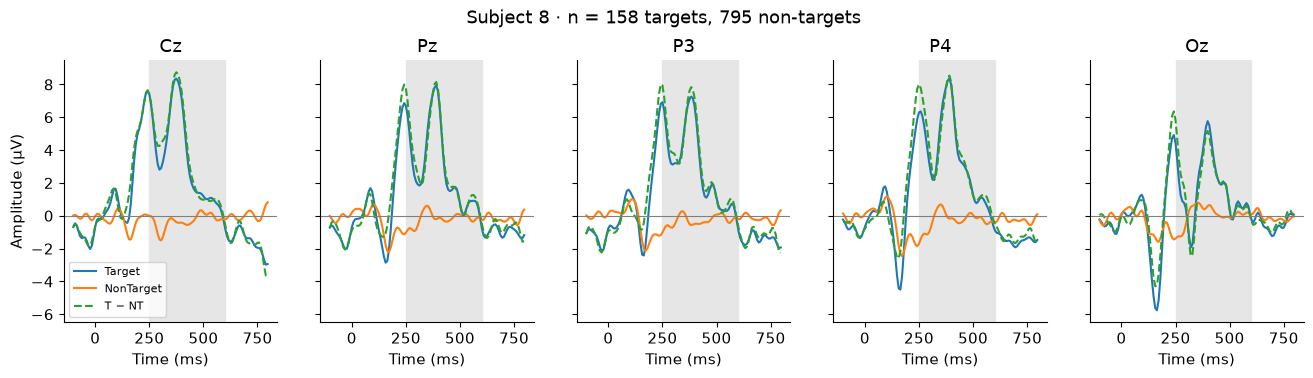

In [21]:
e = erp[example_subject]
fig, axes = plt.subplots(1, len(ERP_CHANNELS), figsize=(16, 3.4), sharey=True)
for ax, ch in zip(axes, ERP_CHANNELS):
    for ev, name, style in [(e['target'], 'Target', '-'), (e['nontarget'], 'NonTarget', '-'),
                            (e['diff'], 'T − NT', '--')]:
        ax.plot(ev.times * 1e3, ev.get_data(picks=[ch])[0] * 1e6, style, label=name)
    ax.axvspan(*(np.array(P300_WINDOW) * 1e3), color='0.9', zorder=0)
    ax.axhline(0, color='0.5', lw=0.8)
    ax.set(title=ch, xlabel='Time (ms)')
axes[0].set_ylabel('Amplitude (µV)')
axes[0].legend(fontsize=8)
fig.suptitle(f'Subject {example_subject} · n = {len(e["epochs"]["Target"])} targets, '
             f'{len(e["epochs"]["NonTarget"])} non-targets', y=1.03)
plt.show()

### 4.2 · Single-trial view at Pz (targets only)
An average can hide whether the response is consistent or driven by a few trials
(notebook 01, Practice 3). The ERP image stacks every target epoch at Pz; a vertical band
in the window means the P300 appears trial after trial.

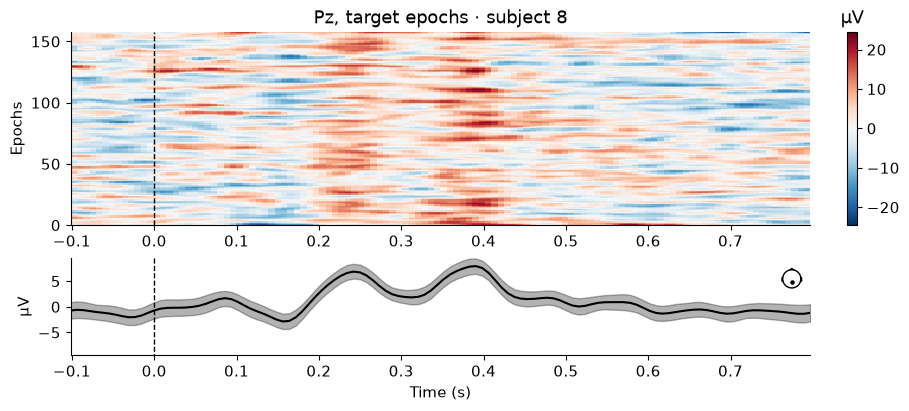

In [22]:
fig = e['epochs']['Target'].plot_image(picks=['Pz'], sigma=1.0, show=False,
                                       title=f'Pz, target epochs · subject {example_subject}')
plt.show()

### 4.3 · Group difference wave and its topography
Each subject's Pz difference wave appears as a thin line, with the grand average in bold.
The topographies show the grand-average difference at fixed latencies. Fp1/Fp2 are
included so that any residual frontal (ocular) difference after ICA stays visible.

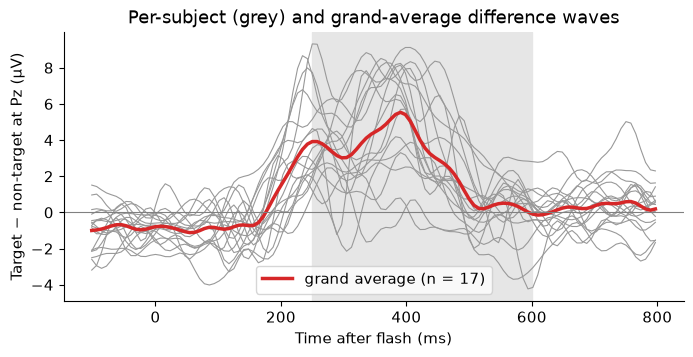

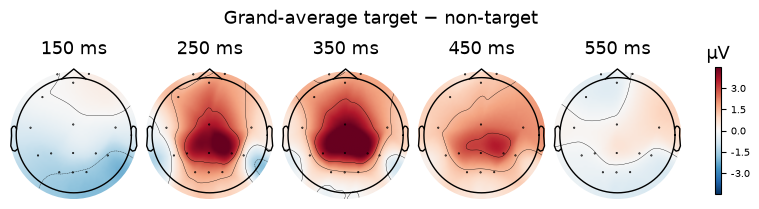

In [23]:
fig, ax = plt.subplots(figsize=(8, 3.5))
for subject, e_s in erp.items():
    ax.plot(times * 1e3, e_s['diff'].get_data(picks=['Pz'])[0] * 1e6, color='0.6', lw=0.8)
ax.plot(times * 1e3, grand_diff.get_data(picks=['Pz'])[0] * 1e6, color='C3', lw=2.5,
        label=f'grand average (n = {len(erp)})')
ax.axvspan(*(np.array(P300_WINDOW) * 1e3), color='0.9', zorder=0)
ax.axhline(0, color='0.5', lw=0.8)
ax.set(xlabel='Time after flash (ms)', ylabel='Target − non-target at Pz (µV)',
       title='Per-subject (grey) and grand-average difference waves')
ax.legend()
plt.show()

fig = grand_diff.plot_topomap(times=[0.15, 0.25, 0.35, 0.45, 0.55], ch_type='eeg',
                              time_unit='ms', show=False)
fig.suptitle('Grand-average target − non-target', y=1.05)
plt.show()

### Stage 4 findings
Use the per-subject table and group test above for the actual P300 evidence. The
window (250-600 ms at Pz) stays fixed for every subject. Peak latency and amplitude
are descriptive quantities, not features selected to maximize decoding.

Single-epoch label permutations ignore dependence between overlapping responses.
Treat these p-values as descriptive. The subject-level test is the main signal check.

## 5 · Features and classifier (notebook 02)
Every choice below is fixed **before** the first decoding result is seen, and none is
tuned afterwards.

| Choice | Value | Reason |
|---|---|---|
| Features | Mean amplitudes in 16 consecutive 50 ms windows over 0-800 ms | Workshop 01-02 ERP features; fixed before the full run |
| Channels | Fixed Cz, P3, Pz, P4, Oz: five physiological P300 sites, 80 features | No channel selection from held-out data; pilot-informed choice |
| Pipeline | `FunctionTransformer(window means)` → `StandardScaler` → `LinearDiscriminantAnalysis(solver='lsqr', shrinkage='auto')` | One scikit-learn `Pipeline` (notebook 02), so the scaling and the covariance shrinkage are learned on training folds only. |
| Hyper-parameters | None tuned | Analytic shrinkage fits each training fold; the montage and windows are frozen before the full run |
| Within-subject CV | `LeaveOneGroupOut` with group = run (2 folds) | One run trains, the other tests. Epochs from one run never land on both sides, and filtering and ICA were already done per run. A random epoch split would leak, because overlapping flashes share samples. |
| Metrics | **ROC AUC** (primary), balanced accuracy | Classes are 1 : 5. AUC ranks the continuous LDA scores. Balanced accuracy uses the default decision rule, with LDA priors from training prevalence (notebook 02), and no threshold tuning. |
| Chance level | `permutation_test_score`, 200 label shuffles **within each run** | This is the empirical null for AUC under the same CV; the smallest possible p is 1/201 ≈ 0.005. |

Stage 6 reuses this exact pipeline for the LOSO conditions. This stage gives the
subject-specific (**Within**) baseline.

In [24]:
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.model_selection import LeaveOneGroupOut, cross_validate, permutation_test_score
from sklearn.metrics import roc_auc_score, balanced_accuracy_score, ConfusionMatrixDisplay

FEATURE_WINDOWS = [(round(a, 2), round(a + 0.05, 2)) for a in np.arange(0.0, 0.8, 0.05)]
EPOCH_CHANNELS = next(iter(epochs_by_run.values())).ch_names          # the 16 EEG channels
# Fixed physiological montage, frozen before the 17-subject run. No held-out subject
# determines which training features exist. These five sites were already specified
# for the P300 check. This revision follows the earlier three-subject development run.
FEATURE_CHANNELS = ['Cz', 'P3', 'Pz', 'P4', 'Oz']
assert all(not set(ep.info['bads']) & set(FEATURE_CHANNELS) for ep in epochs_by_run.values()), 'core montage needs QC review'
EPOCH_TIMES = next(iter(epochs_by_run.values())).times
assert all(((EPOCH_TIMES >= a) & (EPOCH_TIMES < b)).sum() >= 5 for a, b in FEATURE_WINDOWS)
N_PERM_DECODE = 200


def erp_window_means(X, times=EPOCH_TIMES, windows=FEATURE_WINDOWS):
    """(n_epochs, n_channels, n_times) → (n_epochs, n_channels × n_windows); stateless."""
    feats = [X[:, :, (times >= a) & (times < b)].mean(axis=-1) for a, b in windows]
    return np.concatenate(feats, axis=1)


PIPE = Pipeline([
    ('erp_windows', FunctionTransformer(erp_window_means)),
    ('scale', StandardScaler()),
    ('lda', LinearDiscriminantAnalysis(solver='lsqr', shrinkage='auto')),
])


def to_xy(epochs_list):
    """Stack epochs → X (n, 14, t), y (1 = Target), metadata with subject / run groups."""
    X = np.concatenate([ep.get_data(picks=FEATURE_CHANNELS) for ep in epochs_list])
    meta = pd.concat([ep.metadata for ep in epochs_list], ignore_index=True)
    y = (meta['label'] == 'Target').to_numpy().astype(int)
    assert len(X) == len(y) == len(meta)
    return X, y, meta


print(f'{len(FEATURE_CHANNELS)} channels: {FEATURE_CHANNELS}')
print(f'{len(FEATURE_WINDOWS)} windows of 50 ms → {len(FEATURE_CHANNELS) * len(FEATURE_WINDOWS)} features')
X_demo, y_demo, _ = to_xy([epochs_by_run[(example_subject, example_run)]])
print('Feature matrix for one run:', PIPE[:1].fit_transform(X_demo).shape)

5 channels: ['Cz', 'P3', 'Pz', 'P4', 'Oz']
16 windows of 50 ms → 80 features
Feature matrix for one run: (478, 80)


### 5.1 · What the features carry (example subject, descriptive)
The heat map shows the target − non-target difference of each feature (channel × window).
It shows where the information sits. It is not used to select features.

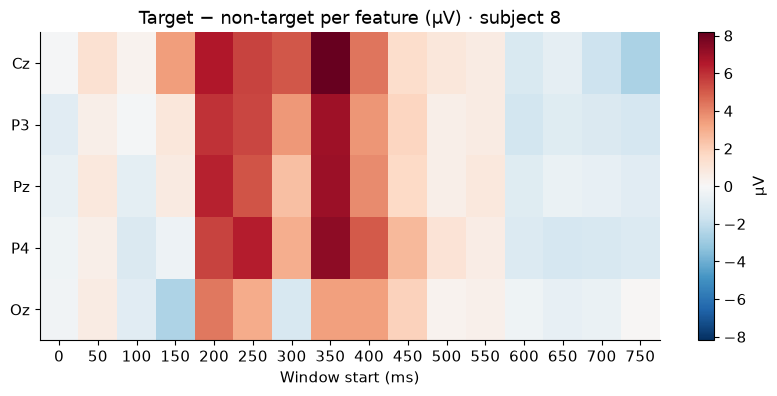

In [25]:
X_s, y_s, meta_s = to_xy([ep for (s, _), ep in epochs_by_run.items() if s == example_subject])
# Features are ordered window-major: [w0: ch0..ch13, w1: ch0..ch13, ...] → (n, window, channel).
F = erp_window_means(X_s).reshape(len(X_s), len(FEATURE_WINDOWS), len(FEATURE_CHANNELS)).transpose(0, 2, 1)
# Cross-check against a direct window mean at Pz in 300–350 ms.
i_pz, i_w = FEATURE_CHANNELS.index('Pz'), FEATURE_WINDOWS.index((0.3, 0.35))
direct = X_s[:, FEATURE_CHANNELS.index('Pz'), (EPOCH_TIMES >= 0.3) & (EPOCH_TIMES < 0.35)].mean(-1)
assert np.allclose(F[:, i_pz, i_w], direct)
diff_map = (F[y_s == 1].mean(0) - F[y_s == 0].mean(0)) * 1e6
fig, ax = plt.subplots(figsize=(10, 4))
lim = np.abs(diff_map).max()
im = ax.imshow(diff_map, aspect='auto', cmap='RdBu_r', vmin=-lim, vmax=lim)
ax.set(yticks=range(len(FEATURE_CHANNELS)), yticklabels=FEATURE_CHANNELS,
       xticks=range(len(FEATURE_WINDOWS)), xticklabels=[f'{int(a * 1e3)}' for a, _ in FEATURE_WINDOWS],
       xlabel='Window start (ms)', title=f'Target − non-target per feature (µV) · subject {example_subject}')
plt.colorbar(im, ax=ax, label='µV')
plt.show()

### 5.2 · Within-subject decoding (leave-one-run-out) with a permutation chance level

In [26]:
def within_subject(subject, n_perm=N_PERM_DECODE):
    """LORO decoding for one subject: per-test-run scores + permutation p for AUC."""
    X, y, meta = to_xy([ep for (s, _), ep in epochs_by_run.items() if s == subject])
    groups = meta['run'].to_numpy()
    logo = LeaveOneGroupOut()
    cv = cross_validate(clone(PIPE), X, y, groups=groups, cv=logo,
                        scoring={'auc': 'roc_auc', 'bacc': 'balanced_accuracy'})
    test_runs = [np.unique(groups[test])[0] for _, test in logo.split(X, y, groups)]
    auc_obs, null, p = permutation_test_score(clone(PIPE), X, y, groups=groups, cv=logo,
                                              scoring='roc_auc', n_permutations=n_perm,
                                              random_state=SEED)
    folds = pd.DataFrame({'subject': subject, 'test_run': test_runs,
                          'auc': cv['test_auc'], 'bacc': cv['test_bacc']})
    summary = {'subject': subject, 'auc_mean': cv['test_auc'].mean(), 'auc_sd': cv['test_auc'].std(ddof=1),
               'bacc_mean': cv['test_bacc'].mean(), 'perm_p': p,
               'null_95': np.percentile(null, 95), 'null_mean': null.mean()}
    return folds, summary, null


t0 = time.perf_counter()
within_folds, within_rows, nulls = [], [], {}
for subject in AUDIT_SUBJECTS:
    folds, summary, null = within_subject(subject)
    within_folds.append(folds)
    within_rows.append(summary)
    nulls[subject] = null
within_folds = pd.concat(within_folds, ignore_index=True)
within = pd.DataFrame(within_rows).round(3)
print(f'Within-subject decoding, {len(within)} subject(s): {time.perf_counter() - t0:.1f} s\n')
print(within_folds.round(3).to_string(index=False))
print()
print(within.to_string(index=False))
print(f"\nAcross subjects: AUC {within.auc_mean.mean():.3f} ± "
      f"{within.auc_mean.std(ddof=1) if len(within) > 1 else float('nan'):.3f} (mean ± SD), "
      f"{(within.perm_p < 0.05).sum()}/{len(within)} subjects above chance (perm p < .05)")

Within-subject decoding, 17 subject(s): 127.3 s

 subject test_run   auc  bacc
       8        0 0.872 0.727
       8        2 0.896 0.746
       9        0 0.873 0.705
       9        2 0.894 0.741
      10        0 0.871 0.724
      10        2 0.911 0.767
      11        0 0.898 0.749
      11        2 0.928 0.768
      12        0 0.856 0.705
      12        2 0.882 0.715
      13        0 0.898 0.620
      13        2 0.824 0.671
      14        0 0.819 0.630
      14        2 0.845 0.678
      15        0 0.912 0.754
      15        2 0.946 0.818
      16        0 0.925 0.790
      16        2 0.939 0.805
      17        0 0.776 0.607
      17        2 0.848 0.685
      18        0 0.964 0.835
      18        2 0.959 0.852
      19        0 0.803 0.642
      19        2 0.807 0.652
      20        0 0.753 0.569
      20        2 0.765 0.594
      21        0 0.966 0.862
      21        2 0.954 0.804
      22        0 0.883 0.730
      22        2 0.884 0.662
      23        0 0.8

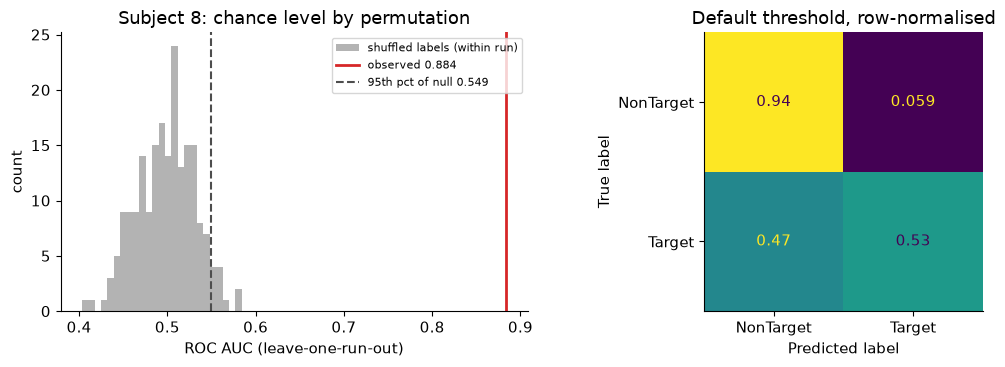

In [27]:
# Permutation null vs observed AUC, and the confusion matrix at the default threshold.
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
row = within.set_index('subject').loc[example_subject]
axes[0].hist(nulls[example_subject], bins=25, color='0.7', label='shuffled labels (within run)')
axes[0].axvline(row.auc_mean, color='C3', lw=2, label=f'observed {row.auc_mean:.3f}')
axes[0].axvline(row.null_95, color='0.3', ls='--', label=f'95th pct of null {row.null_95:.3f}')
axes[0].set(xlabel='ROC AUC (leave-one-run-out)', ylabel='count',
            title=f'Subject {example_subject}: chance level by permutation')
axes[0].legend(fontsize=8)

X_s, y_s, meta_s = to_xy([ep for (s, _), ep in epochs_by_run.items() if s == example_subject])
pred = np.empty_like(y_s)
for train, test in LeaveOneGroupOut().split(X_s, y_s, meta_s['run']):
    pred[test] = clone(PIPE).fit(X_s[train], y_s[train]).predict(X_s[test])
ConfusionMatrixDisplay.from_predictions(y_s, pred, display_labels=['NonTarget', 'Target'],
                                        normalize='true', ax=axes[1], colorbar=False)
axes[1].set_title('Default threshold, row-normalised')
plt.tight_layout()
plt.show()

### Stage 5 findings
The output above reports the actual per-run and per-subject decoding scores.
The fixed five-channel montage has 80 window-mean features. The window transformation
is stateless. Scaling and analytic shrinkage fit only the training fold.

Subjects 8-10 were used in development. This is a pilot-informed retrospective study,
not a prospectively registered confirmatory experiment. Stage 6 reports sensitivity
with those subjects excluded from the evaluation summary.

The two-fold SD is imprecise. Unrestricted within-run label shuffling does not retain
all temporal dependence between overlapping flashes, so permutation significance
is descriptive and should not be presented as an exact randomization test.

## 6 · Hypothesis test: calibration-free (LOSO) vs subject-specific (Within)
For every subject *s* and each of its two training runs *r* as the **test run**:

| Condition | Trained on | Tested on |
|---|---|---|
| **Within** (subject-specific) | the other run of *s* | run *r* of *s* |
| **LOSO** (calibration-free) | all runs of all other subjects | run *r* of *s* |
| **LOSO-matched** (control) | a random subset of the other subjects' epochs with the *same* number of targets and non-targets as Within; mean of 10 draws | run *r* of *s* |

Only the training data change between conditions. The test epochs, features, pipeline (stage
5) and metric are identical. LOSO-matched separates **whose** data train the model from
**how much** data it gets.

**Pre-declared hypotheses** (from the topic registration):
* **H1.** LOSO is above chance on unseen subjects. Per subject and run, we shuffle the
  *test* labels against the fixed LOSO scores 1000 times. This needs no refit, because the
  LOSO model never saw the test subject. At group level, a one-sided Wilcoxon test checks
  that LOSO AUC exceeds 0.5.
* **H2.** Within > LOSO, by a one-sided paired Wilcoxon test across subjects.
* **H3.** Within > LOSO-matched, by a one-sided paired Wilcoxon test. If the gap survives
  equal training sizes, it comes from the *source* of the data, not its amount.
* **Descriptive.** LOSO vs LOSO-matched, two-sided: how much more data from other people
  helps.

**Unit of analysis.** One value per subject: the mean over its two test runs. The two runs
of a subject are not independent observations. Effect sizes are reported as the median
paired difference and the matched-pairs rank-biserial correlation. The rubric asks whether
a difference exceeds fold-to-fold variability, so the paired gap is also compared with the
within-subject spread across the two test runs.

**Leakage checks in code.**
* No epoch of the test subject enters LOSO or LOSO-matched training (assert).
* The scaler and the shrinkage are fitted inside each training set.
* The test subject gets no normalisation of its own: a calibration-free decoder would not
  have that.

In [28]:
from scipy.stats import wilcoxon, rankdata, spearmanr

N_MATCHED_DRAWS = 10
N_PERM_TEST = 1000

# The window-mean step is stateless, so computing it once per run is equivalent to running
# it inside the pipeline; the scaler + LDA part is still fitted per training set.
FEAT = {}
for key, ep in epochs_by_run.items():
    X, y, _ = to_xy([ep])
    FEAT[key] = (erp_window_means(X), y)
CLF = Pipeline(PIPE.steps[1:])                      # StandardScaler → shrinkage LDA


def stack(keys):
    return (np.concatenate([FEAT[k][0] for k in keys]),
            np.concatenate([FEAT[k][1] for k in keys]))


def auc_and_perm_p(scores, y, n_perm=N_PERM_TEST, seed=SEED):
    """AUC from ranks and a one-sided p from shuffling test labels against fixed scores."""
    r = rankdata(scores)
    n1, n0 = int(y.sum()), int(len(y) - y.sum())
    auc = (r[y == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)
    rng_p = np.random.default_rng(seed)
    pos = np.argsort(rng_p.random((n_perm, len(y))), axis=1)[:, :n1]
    null = (r[pos].sum(axis=1) - n1 * (n1 + 1) / 2) / (n1 * n0)
    return auc, (np.sum(null >= auc) + 1) / (n_perm + 1)


t0 = time.perf_counter()
subjects_6 = sorted({s for s, _ in FEAT})
rows6 = []
for s in subjects_6:
    own = sorted(k for k in FEAT if k[0] == s)
    others = [k for k in FEAT if k[0] != s]
    assert s not in {k[0] for k in others}                     # no test-subject epochs
    X_lo, y_lo = stack(others)
    loso_model = clone(CLF).fit(X_lo, y_lo)                    # one LOSO model per subject
    pos_lo, neg_lo = np.where(y_lo == 1)[0], np.where(y_lo == 0)[0]
    for test_key in own:
        X_te, y_te = FEAT[test_key]
        X_w, y_w = stack([k for k in own if k != test_key])
        auc_w = roc_auc_score(y_te, clone(CLF).fit(X_w, y_w).decision_function(X_te))
        auc_l, p_l = auc_and_perm_p(loso_model.decision_function(X_te), y_te)
        n_t, n_nt = int(y_w.sum()), int(len(y_w) - y_w.sum())
        matched = []
        for k in range(N_MATCHED_DRAWS):
            r_k = np.random.default_rng([SEED, s, int(test_key[1]), k])
            pick = np.concatenate([r_k.choice(pos_lo, n_t, replace=False),
                                   r_k.choice(neg_lo, n_nt, replace=False)])
            m = clone(CLF).fit(X_lo[pick], y_lo[pick])
            matched.append(roc_auc_score(y_te, m.decision_function(X_te)))
        rows6.append({'subject': s, 'test_run': test_key[1],
                      'n_train_within': len(y_w), 'n_train_loso': len(y_lo),
                      'within': auc_w, 'loso_matched': np.mean(matched),
                      'loso_matched_sd': np.std(matched, ddof=1), 'loso': auc_l, 'loso_perm_p': p_l})
runs6 = pd.DataFrame(rows6)
print(f'Stage 6 for {len(subjects_6)} subjects: {time.perf_counter() - t0:.1f} s\n')
print(runs6.round(3).to_string(index=False))

# Consistency: Within here must equal the stage-5 cross_validate result on the same folds.
check = runs6.merge(within_folds, on=['subject', 'test_run'])
assert len(check) == len(runs6) and np.allclose(check['within'], check['auc']), 'Within mismatch'

Stage 6 for 17 subjects: 7.8 s

 subject test_run  n_train_within  n_train_loso  within  loso_matched  loso_matched_sd  loso  loso_perm_p
       8        0             475         14943   0.872         0.768            0.042 0.806        0.001
       8        2             478         14943   0.896         0.762            0.046 0.818        0.001
       9        0             479         14938   0.873         0.794            0.030 0.907        0.001
       9        2             479         14938   0.894         0.848            0.014 0.904        0.001
      10        0             477         14940   0.871         0.629            0.056 0.766        0.001
      10        2             479         14940   0.911         0.694            0.038 0.775        0.001
      11        0             473         14946   0.898         0.768            0.048 0.809        0.001
      11        2             477         14946   0.928         0.675            0.059 0.745        0.001
      12      

In [29]:
per_subject6 = runs6.groupby('subject')[['within', 'loso_matched', 'loso']].mean()
per_subject6['loso_runs_p<.05'] = runs6.groupby('subject')['loso_perm_p'].apply(lambda p: int((p < 0.05).sum()))
per_subject6['within_fold_sd'] = runs6.groupby('subject')['within'].std(ddof=1)
per_subject6['loso_fold_sd'] = runs6.groupby('subject')['loso'].std(ddof=1)
per_subject6['loso_matched_fold_sd'] = runs6.groupby('subject')['loso_matched'].std(ddof=1)
print(per_subject6.round(3).to_string())
print('\nAcross subjects (mean ± SD of per-subject AUC):')
for col, name in [('within', 'Within'), ('loso_matched', 'LOSO-matched'), ('loso', 'LOSO')]:
    sd = per_subject6[col].std(ddof=1) if len(per_subject6) > 1 else float('nan')
    print(f'  {name:<13} {per_subject6[col].mean():.3f} ± {sd:.3f}')
condition_summary = pd.DataFrame({col: {
    'mean_subject_auc': per_subject6[col].mean(),
    'sd_subject_auc': per_subject6[col].std(ddof=1),
    'mean_test_fold_auc': runs6[col].mean(),
    'sd_test_fold_auc': runs6[col].std(ddof=1),
    'mean_chance_corrected_auc': 2 * per_subject6[col].mean() - 1,
} for col in ['within', 'loso_matched', 'loso']}).T
print('\nCondition summary (fold spread and subject spread are different quantities):')
print(condition_summary.round(4).to_string())


def paired(a, b, alternative):
    d = np.asarray(a) - np.asarray(b)
    d = d[np.isfinite(d)]
    nonzero = d[d != 0]
    if not len(nonzero):
        return {'n': len(d), 'median_diff': 0., 'mean_diff': 0., 'rank_biserial': 0., 'p': 1.}
    ranks = rankdata(np.abs(nonzero))
    rb = (ranks[nonzero > 0].sum() - ranks[nonzero < 0].sum()) / ranks.sum()
    p = wilcoxon(d, alternative=alternative).pvalue
    return {'n': len(d), 'median_diff': np.median(d), 'mean_diff': d.mean(),
            'rank_biserial': rb, 'p': p}


ps = per_subject6
tests = pd.DataFrame({
    'H1: LOSO > 0.5': paired(ps['loso'], np.full(len(ps), 0.5), 'greater'),
    'H2: Within > LOSO': paired(ps['within'], ps['loso'], 'greater'),
    'H3: Within > LOSO-matched': paired(ps['within'], ps['loso_matched'], 'greater'),
    'LOSO vs LOSO-matched (2-sided)': paired(ps['loso'], ps['loso_matched'], 'two-sided'),
}).T
def holm_adjust(pvalues):
    pvalues = np.asarray(pvalues, dtype=float)
    order = np.argsort(pvalues)
    result = np.empty(len(pvalues))
    result[order] = np.minimum(1., np.maximum.accumulate((len(pvalues) - np.arange(len(pvalues))) * pvalues[order]))
    return result

tests['p_holm_primary'] = np.nan
tests.loc[tests.index[:3], 'p_holm_primary'] = holm_adjust(tests['p'].iloc[:3])
print()
print(tests.round(4).to_string())
new_subjects = ps.loc[~ps.index.isin([8, 9, 10])]
if len(new_subjects) >= MIN_GROUP_N:
    sensitivity = pd.DataFrame({
        'H1: LOSO > 0.5': paired(new_subjects['loso'], np.full(len(new_subjects), .5), 'greater'),
        'H2: Within > LOSO': paired(new_subjects['within'], new_subjects['loso'], 'greater'),
        'H3: Within > LOSO-matched': paired(new_subjects['within'], new_subjects['loso_matched'], 'greater'),
    }).T
    sensitivity['p_holm_primary'] = holm_adjust(sensitivity['p'])
    print('\nSensitivity excluding development subjects 8-10 from evaluation:')
    print(sensitivity.round(5).to_string())
print(f"\nFold-to-fold spread of Within (median SD over the two test runs): "
      f"{ps['within_fold_sd'].median():.3f}; median Within − LOSO gap: "
      f"{(ps['within'] - ps['loso']).median():.3f}")
if len(ps) < MIN_GROUP_N:
    print(f'\nSMOKE TEST with n = {len(ps)} subjects: a one-sided Wilcoxon test cannot reach '
          f'p < .05 below n = 5 (minimum p = {0.5 ** len(ps):.3f} here). Interpret only the full run.')

         within  loso_matched   loso  loso_runs_p<.05  within_fold_sd  loso_fold_sd  loso_matched_fold_sd
subject                                                                                                  
8         0.884         0.765  0.812                2           0.016         0.009                 0.004
9         0.883         0.821  0.906                2           0.015         0.002                 0.038
10        0.891         0.662  0.770                2           0.028         0.006                 0.045
11        0.913         0.721  0.777                2           0.021         0.045                 0.066
12        0.869         0.784  0.856                2           0.018         0.016                 0.024
13        0.861         0.652  0.738                2           0.052         0.088                 0.054
14        0.832         0.626  0.752                2           0.019         0.033                 0.060
15        0.929         0.700  0.862          

### 6.1 · Per-subject view
Each line is one subject: subject-specific, then calibration-free with matched data, then
calibration-free with all data. The dashed line marks chance.

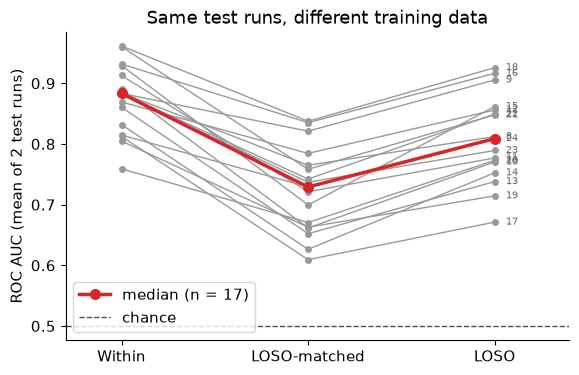

In [30]:
cond_order = ['within', 'loso_matched', 'loso']
cond_names = ['Within', 'LOSO-matched', 'LOSO']
fig, ax = plt.subplots(figsize=(6.5, 4))
for s, row in ps.iterrows():
    ax.plot(range(3), row[cond_order], '-o', color='0.6', ms=4, lw=1)
    ax.text(2.06, row['loso'], str(s), fontsize=7, va='center', color='0.4')
ax.plot(range(3), ps[cond_order].median(), '-o', color='C3', lw=2.5, ms=7,
        label=f'median (n = {len(ps)})')
ax.axhline(0.5, color='0.3', ls='--', lw=1, label='chance')
ax.set(xticks=range(3), xticklabels=cond_names, ylabel='ROC AUC (mean of 2 test runs)',
       xlim=(-0.3, 2.4), title='Same test runs, different training data')
ax.legend(loc='lower left')
plt.show()

### 6.2 · Secondary question: whom does LOSO fail?
Per subject, the LOSO AUC is compared with three things from stage 4: the P300 peak
amplitude, the peak latency, and how similar the subject's difference wave is to the
grand average of the *other* subjects. Spearman correlations are printed only with
≥ 6 subjects. This analysis is exploratory: it explains results, it is not a test of H1–H3.

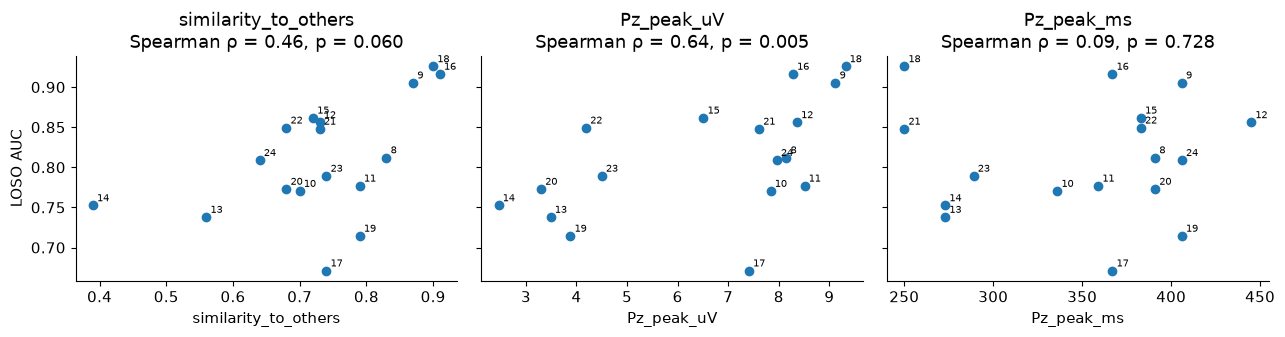

In [31]:
expl = ps.join(erp_table.set_index('subject')[['Pz_peak_uV', 'Pz_peak_ms', 'similarity_to_others']])
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5), sharey=True)
for ax, col in zip(axes, ['similarity_to_others', 'Pz_peak_uV', 'Pz_peak_ms']):
    ax.scatter(expl[col], expl['loso'], color='C0')
    for s, row in expl.iterrows():
        ax.annotate(str(s), (row[col], row['loso']), fontsize=7, xytext=(3, 3), textcoords='offset points')
    title = col
    if len(expl) >= MIN_GROUP_N:
        rho, p = spearmanr(expl[col], expl['loso'])
        title += f'\nSpearman ρ = {rho:.2f}, p = {p:.3f}'
    ax.set(xlabel=col, title=title)
axes[0].set_ylabel('LOSO AUC')
plt.tight_layout()
plt.show()

### Stage 6 interpretation
The tests above, rather than the earlier smoke-test numbers, determine the conclusion.
H1-H3 are directional tests; Holm correction controls the three primary comparisons.
The extra LOSO-versus-matched comparison and ERP correlations are exploratory.

Each subject contributes one mean over two runs. LOSO training sets overlap, creating
dependence among fitted models. Subject-level Wilcoxon p-values are a conventional
summary for this fixed cohort, not exact population-level guarantees.

The matched control holds class-specific training counts constant, with ten seeded
draws. It changes the source and diversity of training observations together; it does
not isolate every biological cause of transfer loss. AUC measures flash ranking and
does not establish character-selection accuracy, bit rate, or online usability.

## 7 · Reproducibility and machine-readable results
The final cell writes exact tables and a run manifest under results/. The outputs
identify the environment and actual subject list. A local run is not evidence of a
fresh Google Colab run. Installation and analysis timings are reported separately.

For Colab, open the notebook from the repository or upload this file, select a CPU
runtime, restart if installation requests it, then Run all and save the outputs.

In [32]:
import json, platform
elapsed_min = (time.perf_counter() - T_START) / 60
setup_analysis_min = (time.perf_counter() - T_SETUP_START) / 60
versions = {p: metadata.version(p) for p in ['mne', 'moabb', 'numpy', 'scipy', 'pandas', 'scikit-learn', 'matplotlib', 'PyYAML', 'remotezip', 'threadpoolctl']}
print(f'Analysis runtime: {elapsed_min:.2f} min for {len(AUDIT_SUBJECTS)} subjects')
print(f'Setup plus analysis: {setup_analysis_min:.2f} min')
print('Execution environment:', 'Google Colab' if 'google.colab' in sys.modules else 'local CPU')
print(versions)
RESULTS = Path(os.environ.get('BCI_RESULTS', './results'))
RESULTS.mkdir(parents=True, exist_ok=True)
tables = dict(audit=audit, subject_audit=per_subject, filter_measurements=stage2,
              filter_peaks=peaks, qc=qc, erp=erp_table, within_folds=within_folds,
              within_summary=within, comparison_runs=runs6, comparison_subjects=per_subject6,
              condition_summary=condition_summary,
              hypothesis_tests=tests, exploratory=expl,
              artifact_contrast=pd.DataFrame(conf_rows), baseline_audit=pd.DataFrame(prev_rows))
if 'sensitivity' in globals(): tables['sensitivity_tests'] = sensitivity
for name, frame in tables.items(): frame.to_csv(RESULTS / f'{name}.csv', index=True)
manifest = dict(subjects=AUDIT_SUBJECTS, n_subjects=len(AUDIT_SUBJECTS), seed=SEED,
    feature_channels=FEATURE_CHANNELS, feature_windows=FEATURE_WINDOWS, versions=versions,
    analysis_minutes=elapsed_min, setup_analysis_minutes=setup_analysis_min,
    environment='Google Colab' if 'google.colab' in sys.modules else 'local CPU',
    platform=platform.platform(), python=sys.version, native_threadpools=threadpool_info(),
    download_load_seconds=sum(load_seconds.values()), data_prepare_seconds=data_prepare_seconds,
    colab_verified='google.colab' in sys.modules, cold_cache_at_start=COLD_CACHE_AT_START,
    full_planned_cohort=AUDIT_SUBJECTS == SUBJECTS,
    qc_totals=totals.to_dict(), observed_bad_channels=GLOBAL_BADS,
    retained_percent=float(100*(totals.kept_T+totals.kept_NT)/(480*len(qc))))
(RESULTS / 'run_manifest.json').write_text(json.dumps(manifest, indent=2))
print('Saved tables and manifest:', RESULTS.resolve())
print('Primary conclusions with Holm correction:')
for name, row in tests.iloc[:3].iterrows():
    print(name, ':', 'supported in this cohort' if row.p_holm_primary < .05 else 'not established',
          f'(Holm p={row.p_holm_primary:.6g}, median difference={row.median_diff:.4f})')
if 'google.colab' in sys.modules:
    from zipfile import ZipFile, ZIP_DEFLATED
    with ZipFile('ROBT613_results.zip', 'w', compression=ZIP_DEFLATED) as archive:
        for file in sorted(RESULTS.iterdir()):
            if file.is_file() and file.suffix in ('.csv', '.json'):
                archive.write(file, file.name)
    print('Tables archive: ROBT613_results.zip (download from the Colab Files pane)')

Analysis runtime: 7.27 min for 17 subjects
Setup plus analysis: 7.41 min
Execution environment: Google Colab
{'mne': '1.13.2', 'moabb': '1.7.2', 'numpy': '2.5.4', 'scipy': '1.18.1', 'pandas': '2.3.3', 'scikit-learn': '1.9.1', 'matplotlib': '3.11.2', 'PyYAML': '6.0.3', 'remotezip': '0.12.6', 'threadpoolctl': '3.7.0'}
Saved tables and manifest: /content/results
Primary conclusions with Holm correction:
H1: LOSO > 0.5 : supported in this cohort (Holm p=2.28882e-05, median difference=0.3089)
H2: Within > LOSO : supported in this cohort (Holm p=0.000190735, median difference=0.0719)
H3: Within > LOSO-matched : supported in this cohort (Holm p=2.28882e-05, median difference=0.1419)
Tables archive: ROBT613_results.zip (download from the Colab Files pane)


## References
1. E. Vaineau, A. Barachant, A. Andreev, P. C. Rodrigues, G. Cattan, M. Congedo,
   "Brain Invaders adaptive versus non-adaptive P300 brain-computer interface dataset,"
   arXiv:1904.09111, 2019.
2. A. Barachant, M. Congedo, "A plug & play P300 BCI using information geometry,"
   arXiv:1409.0107, 2014.
3. V. Jayaram, A. Barachant, "MOABB: trustworthy algorithm benchmarking for BCIs,"
   J. Neural Eng., vol. 15, no. 6, 066011, 2018.
4. B. Aristimunha et al., "Mother of all BCI Benchmarks," Zenodo,
   doi:10.5281/zenodo.10034223 (software; both entries from moabb.neurotechx.com/docs/cite.html).

5. J. Kim and S.-P. Kim, "A Plug-and-Play P300-Based BCI With Zero-Training
   Application," IEEE TNSRE, vol. 33, pp. 3443-3454, 2025.
   https://doi.org/10.1109/TNSRE.2025.3603979.
6. B. Abibullaev, "ROBT613 BCI Workshop: Brain-Computer Interfaces with MNE-Python,"
   notebooks 00-06. https://github.com/berdakh/ROBT613-BCI-Workshop

The 2014 information-geometry paper motivates generic initialization and adaptation.
The 2025 study motivates testing practical transfer, but uses methods outside this
project's core scope. We implement neither method and do not compare their
device-control accuracy directly with our offline flash-level AUC.

## AI tools disclosure
* **OpenAI Codex**: code review, debugging, API lookup, implementation changes to the
  helpers in this notebook, statistical checks, plotting, and drafting report and slide text.
* **Claude Code (Anthropic)**: checking the submission against the assignment
  requirements, editing report and README wording, and writing the slide generator.

No AI tool generated results, citations or dataset facts. Every number in the report
and slides is exported from this executed notebook. All team members reviewed the
code and can explain every line.